The purpose of this notebook to create the insertion pipeline
The tool receives the multiple views of general object and a prompt to generate new object



imports



In [2]:
from pathlib import Path
import os
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path

from prompts import *
from utils import _convert_trimesh_to_o3d

# Keep relative input and output paths anchored at the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
if not (PROJECT_ROOT / "utils.py").is_file():
    raise RuntimeError(f"Open this notebook from the project root or experiments/: {Path.cwd()}")
os.chdir(PROJECT_ROOT)

from utils import *



### 0. Ojbect preparation



In [3]:
objaverse_dataset = ObjaverseDataset(category="duck", limit=1)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)



dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

In [4]:
current_object = objaverse_dataset[0] # obj_path, vertices, faces
mesh = current_object["mesh"]
mesh.show()



=== Processing UID: b5c9d06f19be4c92a1708515f6655573 ===
FEngine (64 bits) created at 0x33c097c00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


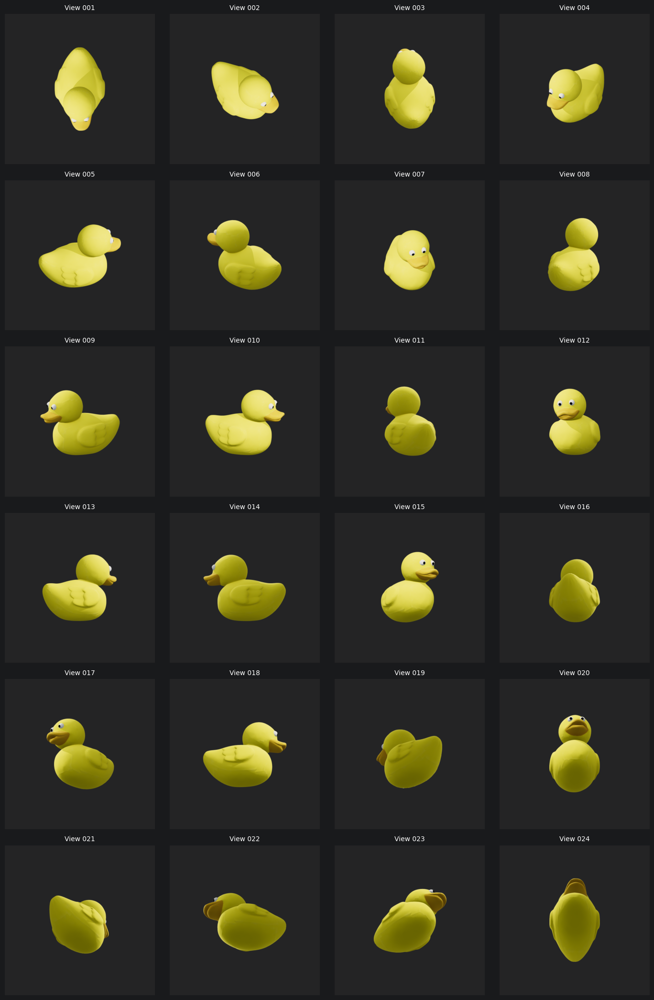

In [5]:
uid_value = current_object["uid"]
uid = uid_value[0] if isinstance(uid_value, (list, tuple)) else uid_value
print(f"=== Processing UID: {uid} ===")
mesh = current_object["mesh"][0] if isinstance(current_object["mesh"], list) else current_object["mesh"]
output_dir = f"rendered_views/{uid}"
rendered_info = render_n_views(mesh, n_views=24, output_dir=output_dir, frame_scale=1.8)
show_rendered_grid(output_dir)



#### 0.1) Input.
Now, the tool should receive the prompt which object should be generated



In [6]:
# prompt = "left bunny ear"
prompt = "car wheel" # what should be generated
directions = ["left"] # where should it be put
rendered_info = rendered_info # all views
image_path = f"generated_images/Flux2_dev_00012_.png" # path of image for 3d object (used for naming)
new_object_mesh_path = "generated_models/ComfyUI_00032.glb" # path to 3d object



Now the 3d object for the prompt should be generated



In [7]:
# image_path = generate_image_from_text(prompt)
# new_object_mesh_path = generate_3d_object_from_image(image_path)
# new_object_mesh = trimesh.load(new_object_mesh_path)





In [8]:
# new_object_mesh.show()



### 1) Now, render new object from 6 views to give agent a better understanding about the structure of new object



FEngine (64 bits) created at 0x33c107600 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


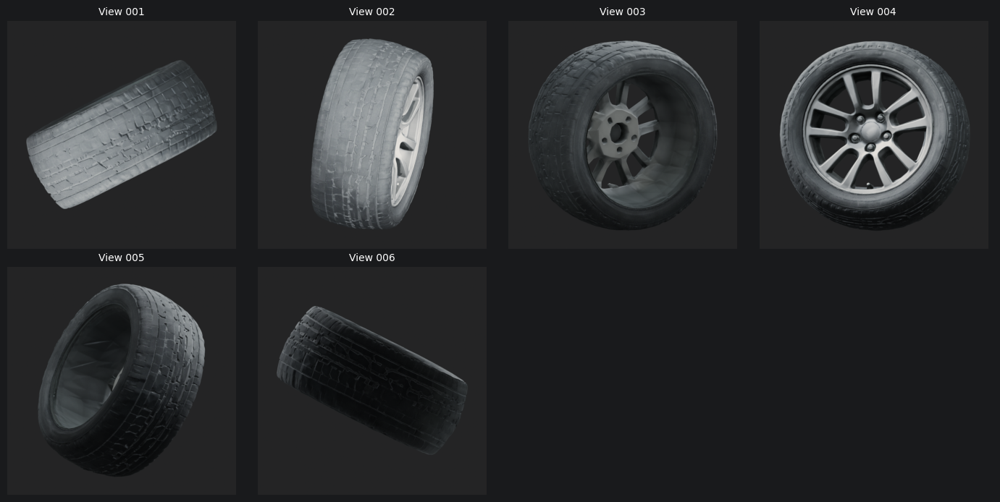

In [9]:
output_dir = f"rendered_new_object_views/{Path(image_path).stem}"
new_object_mesh = trimesh.load("generated_models/ComfyUI_00032.glb")
rendered_new_object_info = render_n_views(new_object_mesh, n_views=6, output_dir=output_dir, is_objaverse_model=False)
show_rendered_grid(output_dir)



### 2) Figure out the center of figure and give each view a direction (left, up, left-up, etc.



We have to give each view a direction from: front, left, right, back, up, down, back-right-up, front-left-down, front-up-left, etc



Since objects may not be aligned in the way that the model will always be rendered from forward, but may be rotated, we ask a VLM to choose from all view the view which the most fits "forward" view. From this based on eyes we can give direction to all other views



In [10]:
FRONT_VIEW_SELECTION_SYSTEM_PROMPT = """
You are a visual reasoning model for 3D object editing.

The input image contains numbered views of the
same 3D object from different camera positions.

Identify the view that most directly shows
the object's intrinsic front side.

The object may have an arbitrary 3D orientation.
Do not assume that it is standing upright.

Compare all views and identify characteristic
features that indicate the object's front.

Return a JSON object with the following fields:
- reasoning: a brief explanation of your selection.
- front_view: the integer ID of the selected view.
"""



In [11]:
from PIL import ImageDraw
def create_views_grid(rendered_info, cols=6, size=320):
    """
    Create a numbered grid of rendered views. So that model has access to all views at the same time
    """

    rows = math.ceil(len(rendered_info) / cols)

    grid = Image.new(
        "RGB",
        (cols * size, rows * (size + 30)),
        (35, 35, 35)
    )

    draw = ImageDraw.Draw(grid)

    for i, (_, path) in enumerate(rendered_info):
        image = Image.open(path).convert("RGB")
        image = image.resize((size, size))

        x = (i % cols) * size
        y = (i // cols) * (size + 30)

        grid.paste(image, (x, y + 30))
        draw.text(
            (x + 10, y + 8),
            f"View {i + 1:03d}",
            fill="white"
        )

    return grid



In [12]:
def estimate_object_orientation(
    mesh,
    rendered_info,
    grid_path,
    ollama_host,
    model_name="qwen3-vl:8b-instruct"
):
    """Estimate object-centric coordinate axes."""

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": FRONT_VIEW_SELECTION_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": "Identify the most frontal view.",
                "images": [str(grid_path)]
            }
        ],
        format="json",
        options={
            "temperature": 0.05,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])
    print("VLM response:", result)

    front_idx = int(result["front_view"]) - 1

    # display(Image.open(rendered_info[front_idx][1]))

    if not 0 <= front_idx < len(rendered_info):
        raise ValueError("Invalid front view index")

    # Use the same mesh center as the renderer
    mesh_o3d = _convert_trimesh_to_o3d(mesh)
    center = mesh_o3d.get_axis_aligned_bounding_box().get_center()

    eye_pos, _ = rendered_info[front_idx]

    # Assume Y-up orientation
    up = np.array([0., 1., 0.])

    # Project front direction onto the horizontal plane
    front = np.asarray(eye_pos) - center
    front -= np.dot(front, up) * up

    if np.linalg.norm(front) < 1e-8:
        raise ValueError("Invalid frontal camera direction")

    front /= np.linalg.norm(front)

    # Compute anatomical directions
    left = np.cross(up, front)
    left /= np.linalg.norm(left)

    return {
        "center": center,
        "front_view_idx": front_idx,
        "front": front,
        "back": -front,
        "left": left,
        "right": -left,
        "up": up,
        "down": -up
    }



In [13]:
def classify_views(rendered_info, orientation, threshold=0.35):
    """
    Classify camera views using object-centric axes. No VLM is used
    Example output:
    {
    "index": 8,
    "eye_pos": array([1.8, 0.9, 1.2]),
    "path": "rendered_views/view_009.png",
    "labels": ["front", "left", "up"],
    "scores": {
        "front": 0.51,
        "back": -0.51,
        "left": 0.77,
        "right": -0.77,
        "up": 0.38,
        "down": -0.38
    }
}
    """

    directions = [
        "front", "back",
        "left", "right",
        "up", "down"
    ]

    center = orientation["center"]
    classified_views = []

    for i, (eye_pos, path) in enumerate(rendered_info):

        camera_dir = np.asarray(eye_pos) - center
        camera_dir /= np.linalg.norm(camera_dir)
        # scores of each direction are decided by dot product with orientation vector
        scores = {
            name: float(np.dot(camera_dir, orientation[name]))
            for name in directions
        }

        labels = [
            name for name in directions
            if scores[name] >= threshold
        ]

        classified_views.append({
            "index": i,
            "eye_pos": eye_pos,
            "path": path,
            "labels": labels,
            "scores": scores
        })

    return classified_views



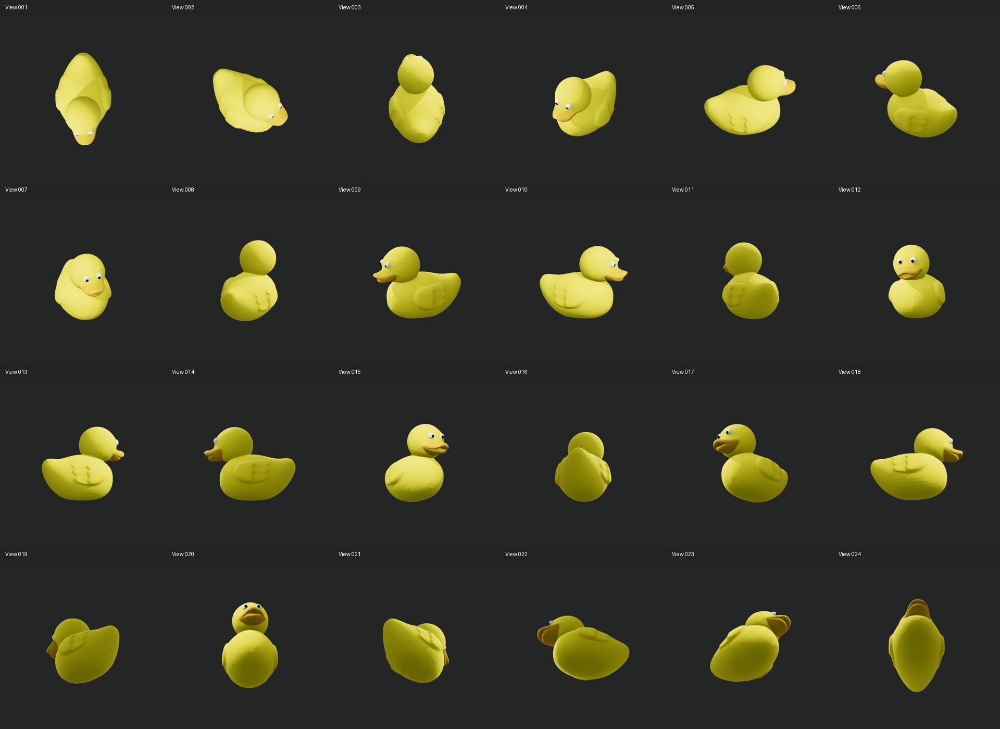

In [14]:
views_grid = create_views_grid(rendered_info)
views_grid.save("views_grid.png")

display(views_grid)



VLM response: {'reasoning': "The most frontal view is the one where the duck's face is directly facing the camera, showing its eyes and beak clearly. View015 shows the duck from the front, with its face centered and oriented directly toward the viewer, making it the most frontal perspective.", 'front_view': 15}
Front view: 15


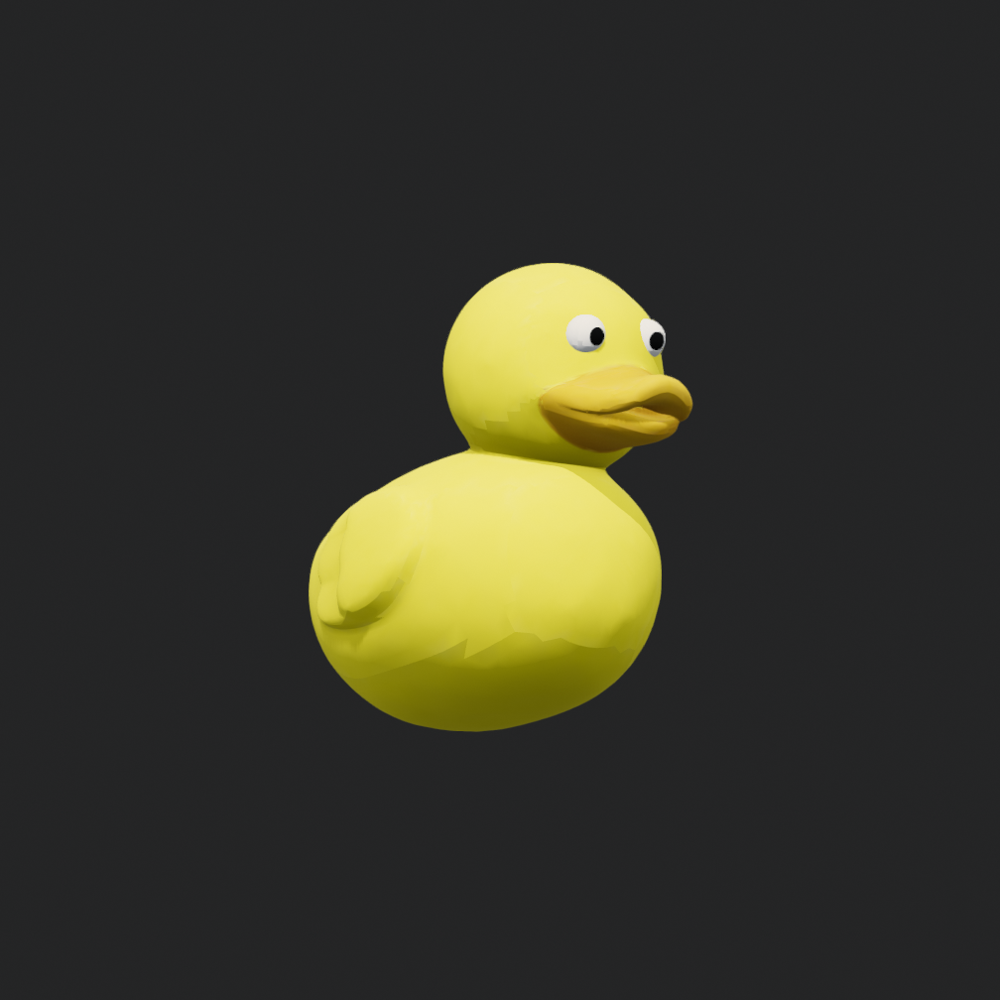

In [15]:
orientation = estimate_object_orientation(
    mesh,
    rendered_info,
    grid_path="views_grid.png",
    ollama_host="192.168.178.23"
)

front_idx = orientation["front_view_idx"]

print(f"Front view: {front_idx + 1}")

display(Image.open(rendered_info[front_idx][1]))



In [16]:
classified_views = classify_views(
    rendered_info,
    orientation
)

for view in classified_views:
    print(
        f"View {view['index'] + 1:03d}: "
        f"{'-'.join(view['labels'])}"
    )



View 001: up
View 002: front-up
View 003: back-up
View 004: left-up
View 005: right-up
View 006: back-up
View 007: front-up
View 008: back-right-up
View 009: left
View 010: front-right
View 011: back
View 012: front-left
View 013: right
View 014: back-left
View 015: front
View 016: back-right
View 017: left-down
View 018: front-right-down
View 019: back-down
View 020: front-left-down
View 021: right-down
View 022: left-down
View 023: front-down
View 024: down


### 3) Select only relevant views for atachment point



In [17]:
def select_relevant_views(
    classified_views,
    directions,
    threshold=0.35,
    max_views=6
):
    """
    Select and rank views matching all requested directions.
    Selection is based on scores for each direction and not labels
    """

    relevant_views = []

    for view in classified_views:
        scores = [
            view["scores"][direction]
            for direction in directions
        ]

        # Check all spatial constraints
        if all(score >= threshold for score in scores):

            relevance = np.mean(scores)

            relevant_views.append(
                (view["index"], relevance)
            )

    # Sort views by relevance
    relevant_views.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return [
        index for index, score
        in relevant_views[:max_views]
    ]



In [18]:
selected_views = select_relevant_views(
    classified_views,
    directions=directions,
    threshold=0.3
)

print("Selected views:")

for i in selected_views:
    print(
        f"View {i + 1:03d}: "
        f"{'-'.join(classified_views[i]['labels'])}"
    )



Selected views:
View 009: left
View 017: left-down
View 012: front-left
View 014: back-left
View 004: left-up
View 022: left-down


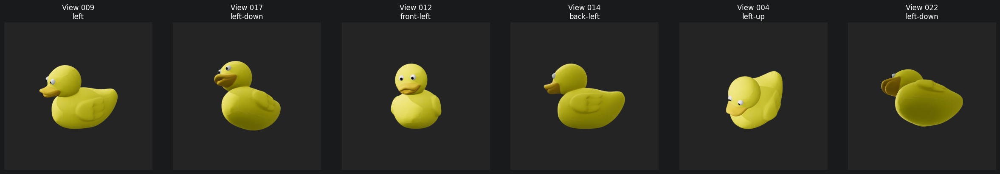

In [19]:
if selected_views:
    fig, axes = plt.subplots(
        1,
        len(selected_views),
        figsize=(4 * len(selected_views), 4),
        squeeze=False
    )

    for ax, i in zip(axes.flat, selected_views):
        view = classified_views[i]

        ax.imshow(Image.open(view["path"]))
        ax.set_title(
            f"View {i + 1:03d}\n"
            f"{'-'.join(view['labels'])}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No relevant views found")



### 4) Generate the attachment point



In [20]:

ATTACHMENT_POINT_SYSTEM_PROMPT = """
You are a visual reasoning model for 3D object editing.

Image 1 shows the original object.
The remaining images show the component to attach.

Imagine the component attached to the original object
according to the user's instructions.

Predict the single point on the original object's
surface where the new component should connect.

The point represents the center of the contact area
between the two objects.

Return coordinates relative to Image 1 only.
Use integer coordinates normalized to [0, 1000].

Return a JSON object with the following fields:
- is_found: boolean
- point_2d: [x, y] or null if not found
"""
def generate_attachment_point(
    ollama_host,
    image_path,
    user_prompt,
    rendered_new_object_info,
    model_name="qwen3-vl:8b-instruct"
):
    """Predict a surface attachment point."""
    reference_images = [element[1] for element in rendered_new_object_info]
    with Image.open(image_path) as image:
        width, height = image.size

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": ATTACHMENT_POINT_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": user_prompt,
                "images": [
                    str(image_path),
                    *[str(path) for path in reference_images]
                ]
            }
        ],
        format="json",
        options={
            "temperature": 0.1,
            "num_ctx": 16384,
            "num_predict": 256
        }
    )

    result = json.loads(response["message"]["content"])

    if not result["is_found"]:
        return None

    x, y = result["point_2d"]

    return (
        round(x / 1000 * (width - 1)),
        round(y / 1000 * (height - 1))
    )




In [21]:
def pixel_to_3d(
    mesh,
    point_2d,
    eye_pos,
    width=1008,
    height=1008,
    frame_scale=1.8
):
    """
    Project a 2D pixel onto the mesh surface using raycasting.
    """

    # Use the same geometry as in render_n_views
    mesh_o3d = _convert_trimesh_to_o3d(mesh)

    bbox = mesh_o3d.get_axis_aligned_bounding_box()
    center = bbox.get_center()
    extent = bbox.get_max_extent()

    half_size = extent / 2 * frame_scale
    aspect = width / height

    # Camera coordinate system
    z_cam = eye_pos - center
    z_cam /= np.linalg.norm(z_cam)

    if abs(z_cam[1]) > 0.99:
        up = np.array([0, 0, -1 if z_cam[1] > 0 else 1])
    else:
        up = np.array([0, 1, 0])

    x_cam = np.cross(up, z_cam)
    x_cam /= np.linalg.norm(x_cam)
    y_cam = np.cross(z_cam, x_cam)

    # Convert pixel coordinates to orthographic coordinates
    px, py = point_2d

    x = (2 * (px + 0.5) / width - 1) * half_size * aspect
    y = (1 - 2 * (py + 0.5) / height) * half_size

    # Construct an orthographic ray
    origin = eye_pos + x * x_cam + y * y_cam
    direction = -z_cam

    ray_mesh = o3d.t.geometry.TriangleMesh.from_legacy(mesh_o3d)

    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(ray_mesh)

    ray = np.concatenate([origin, direction])
    rays = o3d.core.Tensor([ray], dtype=o3d.core.Dtype.Float32)

    hits = scene.cast_rays(rays)

    t_hit = hits["t_hit"].numpy()[0]

    if not np.isfinite(t_hit):
        return None, None

    anchor_point = origin + t_hit * direction
    anchor_normal = hits["primitive_normals"].numpy()[0]

    return anchor_point, anchor_normal




In [22]:
def validate_anchor_point(
    point,
    orientation,
    directions
):
    """
    Check whether a point satisfies spatial constraints.
    """

    relative_point = point - orientation["center"]

    return all(
        np.dot(relative_point, orientation[d]) >= 0
        for d in directions
    )




View 9
2D point: (453, 629)


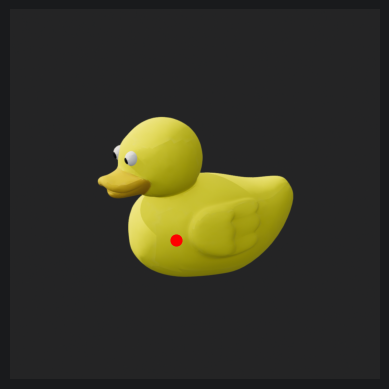

3D point: [ 0.22737058 -0.07390279  0.17542821]

View 17
2D point: (445, 581)


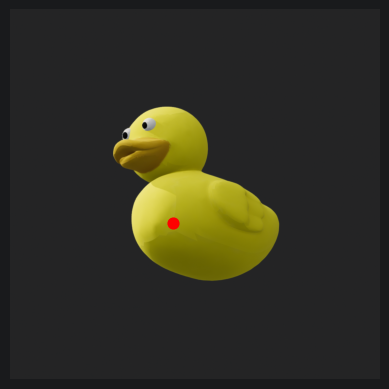

3D point: [ 0.14170902 -0.19251406  0.25211628]

View 12
2D point: (453, 629)


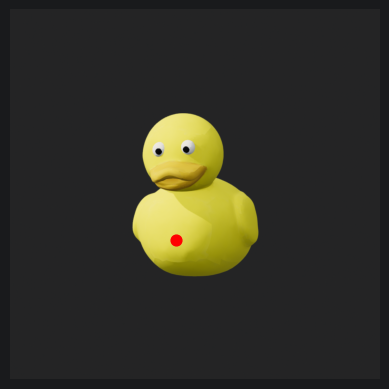

3D point: [ 0.00874095 -0.13690065  0.3236653 ]

View 14
2D point: (440, 581)


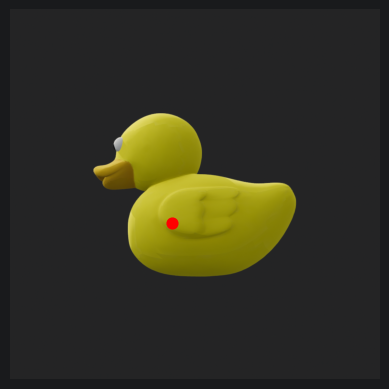

3D point: [ 0.29892095 -0.10274582  0.04716769]

View 4
2D point: (470, 677)


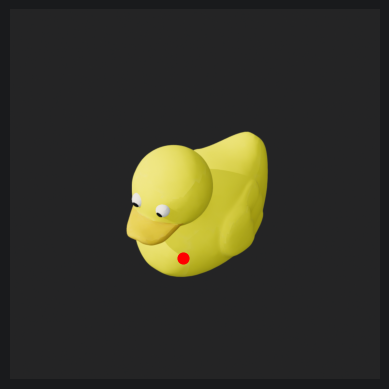

3D point: [ 0.1409721  -0.04758699  0.2779476 ]

View 22
2D point: (453, 604)


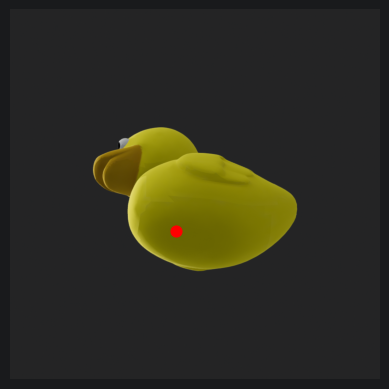

3D point: [ 0.03918407 -0.31946805  0.09280791]
Valid points: 6/24


In [23]:
#TODO: replace hardcoded enhanced prompt with llm request
enhanced_prompt = """
Locate the attachment point for a car wheel
below the visible wing, slightly toward the chest,
on the lower body of the duck.
"""
# we should enhance the prompt via other LLM for better performance

N_BASE_VIEWS = 24
N_PART_VIEWS = 6
FRAME_SCALE = 1.8
OLLAMA_HOST = "192.168.178.23"

anchor_points = []
anchor_normals = []

for i in selected_views:
    eye_pos, view_path = rendered_info[i]

    point_2d = generate_attachment_point(
        ollama_host="192.168.178.23",
        image_path=view_path,
        rendered_new_object_info = rendered_new_object_info,
        user_prompt=enhanced_prompt
    )

    print(f"\nView {i + 1}")
    print("2D point:", point_2d)

    if point_2d is None:
        print("VLM rejected this view")
        continue

    plt.imshow(Image.open(view_path))
    plt.scatter(*point_2d, c="red", s=60)
    plt.axis("off")
    plt.show()

    point_3d, normal = pixel_to_3d(
        mesh,
        point_2d,
        eye_pos,
        frame_scale=1.8
    )

    # if not validate_anchor_point(
    #     point_3d,
    #     orientation,
    #     directions
    # ):
    #     print("Point violates spatial constraints")
    #     continue

    if point_3d is None:
        print("Raycasting missed the mesh")
        continue

    print("3D point:", point_3d)

    anchor_points.append(point_3d)
    anchor_normals.append(normal)

    # plt.imshow(Image.open(view_path))
    # plt.scatter(*point_2d, c="red", s=60)
    # plt.axis("off")
    # plt.show()

anchor_points = np.asarray(anchor_points)
anchor_normals = np.asarray(anchor_normals)

print(f"Valid points: {len(anchor_points)}/{len(rendered_info)}")



In [24]:
scene = trimesh.Scene([mesh])

for point in anchor_points:
    sphere = trimesh.creation.icosphere(
        radius=mesh.extents.max() * 0.015
    )

    sphere.apply_translation(point)
    sphere.visual.face_colors = [255, 0, 0, 255]

    scene.add_geometry(sphere)

scene.show()



In [25]:
from sklearn.cluster import DBSCAN

if len(anchor_points) < 1:
    raise ValueError("Not enough valid anchor points")

labels = DBSCAN(
    eps=mesh.extents.max() * 0.2,
    min_samples=3
).fit_predict(anchor_points)

valid_labels = labels[labels != -1]

if len(valid_labels) == 0:
    raise ValueError("No consistent attachment region found")

best_label = np.bincount(valid_labels).argmax()
indices = np.where(labels == best_label)[0]

cluster_points = anchor_points[indices]
center = cluster_points.mean(axis=0)

# Select the closest actual surface point
best_idx = indices[
    np.argmin(np.linalg.norm(cluster_points - center, axis=1))
]

anchor_point = anchor_points[best_idx]
anchor_normal = anchor_normals[best_idx]



In [26]:
if anchor_point is not None:
    sphere = trimesh.creation.icosphere(
        subdivisions=3,
        radius=mesh.extents.max() * 0.025
    )

    sphere.apply_translation(anchor_point)
    sphere.visual.face_colors = [255, 0, 0, 255]

    scene = trimesh.Scene([mesh, sphere])
    scene.show()



In [27]:
scene.show()



### 5) Generate bounding boxes for object including attachment point



#### Render of model including attachment points



In [28]:
INSERTION_BOUNDING_BOX_SYSTEM_PROMPT = """
Image 1 shows a 3D object with a red attachment marker.
The remaining images show the component to insert.

Imagine the new component attached to the object
at the red marker.

Predict the bounding box of the entire imagined
component, including its occluded portions.

The bounding box may overlap the original object
and extend into the background.

Estimate a suitable size and orientation.

Return coordinates relative to Image 1 only,
using integer coordinates normalized to [0, 1000].

Return only JSON with the following fields:
- is_found: boolean
- bbox_2d: [xmin, ymin, xmax, ymax]

Return is_found=false only if the placement
cannot be estimated at all.
"""


RELATIVE_INSERTION_BBOX_SYSTEM_PROMPT = """
You are a spatial reasoning model for 3D object insertion.

Image 1 shows the original object with an attachment marker.
The remaining images show different views of the component
to be inserted.

Imagine the component physically attached at the given anchor.

The reference images illustrate the component's shape
and appearance, NOT its intended scale.
The component was rendered independently.
Do not transfer its apparent size from the reference images.

Consider:
- The geometry and proportions of the inserted component.
- Its natural size relative to the original object.
- Its orientation after attachment.
- The current camera viewing angle.
- The user request.

Predict the tightest bounding box of the entire imagined
component, including its occluded portions.

The bounding box must contain the attachment anchor,
but the anchor is not necessarily its center.

Do not assume a square bounding box.
Account for the current viewing angle.
Do not surround the original object.

Return absolute image coordinates as integers
normalized to [0, 1000].

Return only JSON:
{
    "xmin": integer,
    "ymin": integer,
    "xmax": integer,
    "ymax": integer
}
"""



In [29]:
def _auto_camera_up(center, eye):
    """
    Place camera to the up
    :param center:
    :param eye:
    :return:
    """
    eye = np.asarray(eye, dtype=float)
    center = np.asarray(center, dtype=float)

    z_cam = eye - center
    z_cam /= np.linalg.norm(z_cam)

    if abs(z_cam[1]) > 0.99:
        return np.array([0.0, 0.0, -1.0]) if z_cam[1] > 0 else np.array([0.0, 0.0, 1.0])
    return np.array([0.0, 1.0, 0.0])



In [30]:
def rendered_info_to_views(mesh_input, rendered_info):
    """
    Converts rendered info to {
        "view_001": (eye_pos, up),
        "view_002": (eye_pos, up),
        ...
    }
    :param mesh_input:
    :param rendered_info:
    :return:
    """
    if isinstance(mesh_input, trimesh.Scene):
        tmesh = mesh_input.dump(concatenate=True)
        mesh_o3d = _convert_trimesh_to_o3d(tmesh, is_objaverse_model=False)
    elif isinstance(mesh_input, trimesh.Trimesh):
        mesh_o3d = _convert_trimesh_to_o3d(mesh_input, is_objaverse_model=False)
    elif isinstance(mesh_input, str):
        mesh_o3d = o3d.io.read_triangle_mesh(mesh_input)
    else:
        mesh_o3d = mesh_input

    center = mesh_o3d.get_axis_aligned_bounding_box().get_center()

    views = {}
    for idx, (eye, _) in enumerate(rendered_info):
        eye = np.asarray(eye, dtype=float)
        up = _auto_camera_up(center, eye)
        views[f"view_{idx + 1:03d}"] = (eye, up)

    return views



In [31]:
def rerender_scene_with_anchor(
    mesh,
    anchor_point,
    rendered_info,
    output_dir="rendered_anchor_views",
    width=1008,
    height=1008,
    frame_scale=1.8,
    marker_radius_ratio=0.025,
):
    """Render the original mesh with a red attachment marker."""

    # Convert the original mesh while preserving colors
    base_mesh = _convert_trimesh_to_o3d(mesh)

    bbox = base_mesh.get_axis_aligned_bounding_box()
    extent = bbox.get_max_extent()

    # Create a red anchor marker
    marker = o3d.geometry.TriangleMesh.create_sphere(
        radius=extent * marker_radius_ratio
    )

    marker.translate(anchor_point)
    marker.paint_uniform_color([1.0, 0.0, 0.0])
    marker.compute_vertex_normals()

    # Combine geometries after color conversion
    scene = base_mesh + marker

    # Restore original camera positions
    views = rendered_info_to_views(base_mesh, rendered_info)

    return render_n_views(
        scene,
        output_dir=output_dir,
        width=width,
        height=height,
        views=views,
        frame_scale=frame_scale,
        is_objaverse_model=False
    )



In [32]:
def _parse_qwen_bbox_response(content, width, height):
    """
    Parses VLM response to collect bounding box coordinates
    :param content:
    :param width:
    :param height:
    :return:
    """
    try:
        result = json.loads(content)
    except json.JSONDecodeError as exc:
        raise ValueError(f"Invalid JSON: {content[:500]!r}") from exc

    if not isinstance(result, dict):
        raise ValueError(f"Invalid response type: {type(result)}")

    if type(result.get("is_found")) is not bool:
        raise ValueError(f"Missing/invalid is_found: {result}")

    if result["is_found"] is False:
        return {"is_found": False, "bbox_2d": None}

    bbox = result.get("bbox_2d")
    if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
        raise ValueError(f"Invalid bbox_2d: {bbox}")

    coords = [float(v) for v in bbox]

    if not all(0 <= v <= 1000 for v in coords):
        raise ValueError(f"Coordinates outside [0,1000]: {bbox}")

    x1, y1, x2, y2 = coords
    x1 = round(x1 * width / 1000)
    y1 = round(y1 * height / 1000)
    x2 = round(x2 * width / 1000)
    y2 = round(y2 * height / 1000)

    x1 = max(0, min(width - 1, x1))
    y1 = max(0, min(height - 1, y1))
    x2 = max(0, min(width - 1, x2))
    y2 = max(0, min(height - 1, y2))

    if x1 >= x2 or y1 >= y2:
        raise ValueError(f"Collapsed/inverted bbox: {[x1, y1, x2, y2]}")

    return {"is_found": True, "bbox_2d": [x1, y1, x2, y2]}



In [33]:
def generate_insertion_bounding_box_for_image(
    ollama_host,
    image_path,
    inserted_object_image_paths,
    user_prompt,
    model_name="qwen3-vl:8b-instruct",
    temperature=0.1,
    num_ctx=16384,
    max_reference_views=3,
):
    """
    Generates bounding box for one view
    :param ollama_host: ip of server with ollama
    :param image_path: path to view
    :param inserted_object_image_paths: paths to object that should be added
    :param user_prompt: prompt given to the tool
    :param model_name: name of the VLM model
    :param temperature:
    :param num_ctx:
    :param max_reference_views:
    :return:
    """
    with Image.open(image_path) as image:
        width, height = image.size

    reference_paths = [str(p) for p in inserted_object_image_paths[:max_reference_views]]
    images = [str(image_path)] + reference_paths

    content = f"""
    Image 1 shows the target object with a red anchor marker.
    The new component must be attached at the red marker.

    User request:
    {user_prompt}

    Return a bounding box for the imagined inserted component only in Image 1.
    If this view is not suitable or the placement cannot be estimated reliably, return is_found=false.
    """

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": INSERTION_BOUNDING_BOX_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": content,
                "images": images
            }
        ],
        format="json",
        think=False,
        options={
            "temperature": temperature,
            "num_ctx": num_ctx
        }
    )

    parsed = _parse_qwen_bbox_response(
        response["message"]["content"],
        width=width,
        height=height
    )

    return json.dumps(parsed)



In [34]:
def generate_insertion_bounding_boxes(
    ollama_host,
    rendered_anchor_info,
    inserted_object_image_paths,
    user_prompt,
    model_name="qwen3-vl:8b-instruct",
    temperature=0.1,
    num_ctx=16384,
    max_reference_views=3,
):
    """
    Generates bounding box for each view
    :param ollama_host:
    :param rendered_anchor_info:
    :param inserted_object_image_paths:
    :param user_prompt:
    :param model_name:
    :param temperature:
    :param num_ctx:
    :param max_reference_views:
    :return:
    """
    results = []

    for view_idx, (eye_pos, image_path) in enumerate(rendered_anchor_info):
        try:
            raw = generate_insertion_bounding_box_for_image(
                ollama_host=ollama_host,
                image_path=image_path,
                inserted_object_image_paths=inserted_object_image_paths,
                user_prompt=user_prompt,
                model_name=model_name,
                temperature=temperature,
                num_ctx=num_ctx,
                max_reference_views=max_reference_views,
            )
            parsed = json.loads(raw)
        except Exception as exc:
            parsed = {
                "is_found": False,
                "bbox_2d": None,
                "error": str(exc),
            }

        parsed["view_idx"] = view_idx
        parsed["eye_pos"] = np.asarray(eye_pos).tolist()
        parsed["image_path"] = image_path
        results.append(parsed)

    return results



In [35]:
def visualize_bbox_result(image_path, bbox_result):
    """
    Visualizes bounding box result
    :param image_path:
    :param bbox_result:
    :return:
    """
    image = np.array(Image.open(image_path).convert("RGB"))

    plt.figure(figsize=(8, 8))
    plt.imshow(image)

    if bbox_result.get("is_found") and bbox_result.get("bbox_2d") is not None:
        x1, y1, x2, y2 = bbox_result["bbox_2d"]
        plt.gca().add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                edgecolor="yellow",
                facecolor="none",
                linewidth=2
            )
        )

    plt.axis("off")
    plt.show()



In [36]:
anchor_rendered_info = rerender_scene_with_anchor(
    mesh=mesh,
    anchor_point=anchor_point,
    rendered_info=rendered_info,
    output_dir="rendered_anchor_views",
    frame_scale=1.8,
)
anchor_rendered_info



FEngine (64 bits) created at 0x33bc48000 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


[(array([ 6.75043758e-04,  2.27373376e+00, -3.36460363e-03]),
  'rendered_anchor_views/view_001.png'),
 (array([-0.66096379,  2.08242941,  0.60275076]),
  'rendered_anchor_views/view_002.png'),
 (array([ 0.10906492,  1.89112506, -1.23841136]),
  'rendered_anchor_views/view_003.png'),
 (array([0.90228232, 1.69982071, 1.17262244]),
  'rendered_anchor_views/view_004.png'),
 (array([-1.64158347,  1.50851637, -0.29385701]),
  'rendered_anchor_views/view_005.png'),
 (array([ 1.53198324,  1.31721202, -0.97745753]),
  'rendered_anchor_views/view_006.png'),
 (array([-0.50090104,  1.12590767,  1.86247341]),
  'rendered_anchor_views/view_007.png'),
 (array([-0.93246576,  0.93460332, -1.80007043]),
  'rendered_anchor_views/view_008.png'),
 (array([1.96914881, 0.74329897, 0.71551886]),
  'rendered_anchor_views/view_009.png'),
 (array([-1.98425164,  0.55199463,  0.81598428]),
  'rendered_anchor_views/view_010.png'),
 (array([ 0.92517012,  0.36069028, -1.97895687]),
  'rendered_anchor_views/view_011.

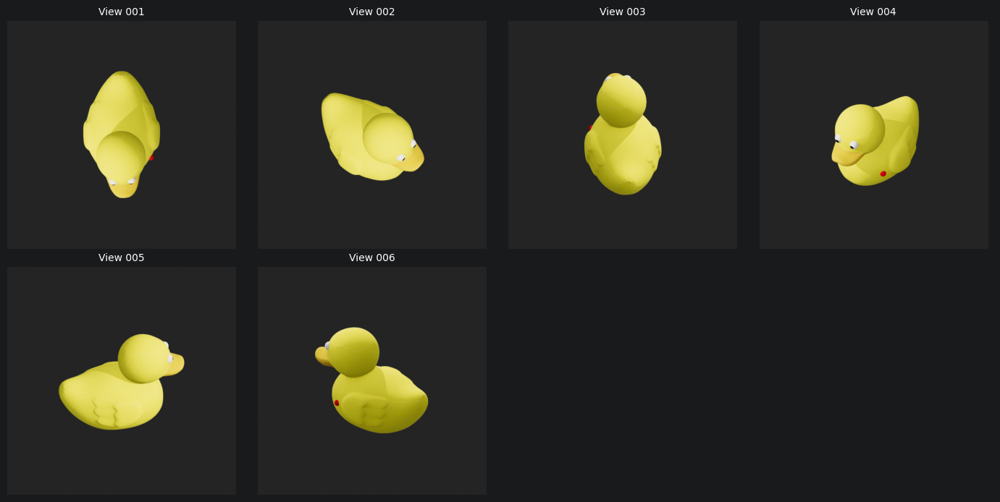

In [37]:
output_dir = f"rendered_anchor_views"
show_rendered_grid(output_dir,6)



In [38]:
inserted_object_image_paths = [
    path for _, path in rendered_new_object_info[:3]
]



In [39]:
bbox_prompt = """
Imagine a single car wheel mounted on the duck
at the red marker.

Predict the rectangular image region that would
be occupied by the wheel after insertion.

The wheel is smaller than the duck.
The wheel touches the red marker.

Do not detect or surround the duck itself.
"""
bbox_results = generate_insertion_bounding_boxes(
    ollama_host="192.168.178.23",
    rendered_anchor_info=anchor_rendered_info,
    inserted_object_image_paths=inserted_object_image_paths,
    user_prompt=bbox_prompt,
    max_reference_views=3,
    num_ctx=16384,
)



Valid bbox predictions: 24/24
View 001 -> [403, 554, 655, 756]


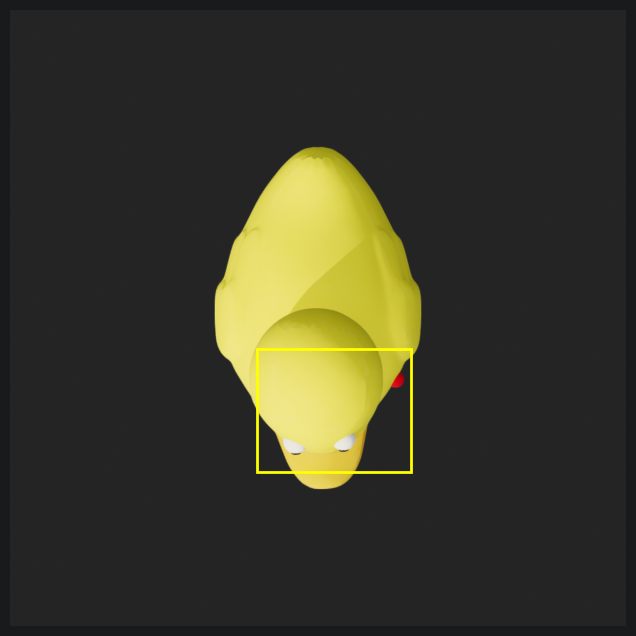

View 002 -> [302, 353, 605, 655]


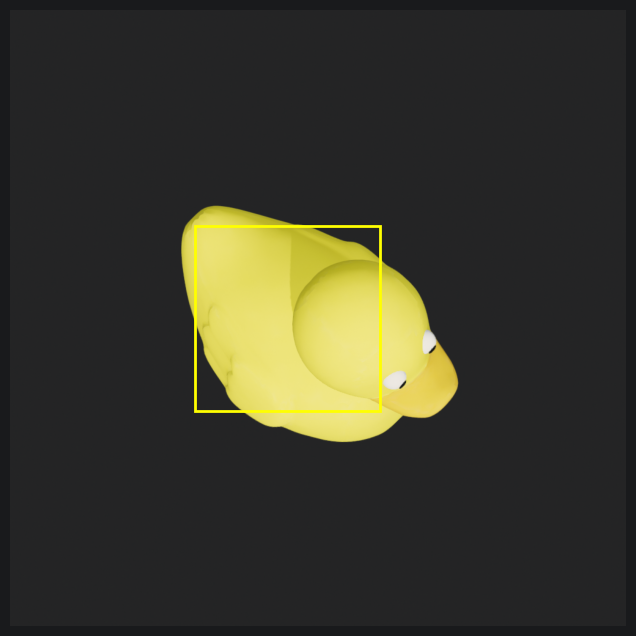

View 003 -> [328, 444, 680, 766]


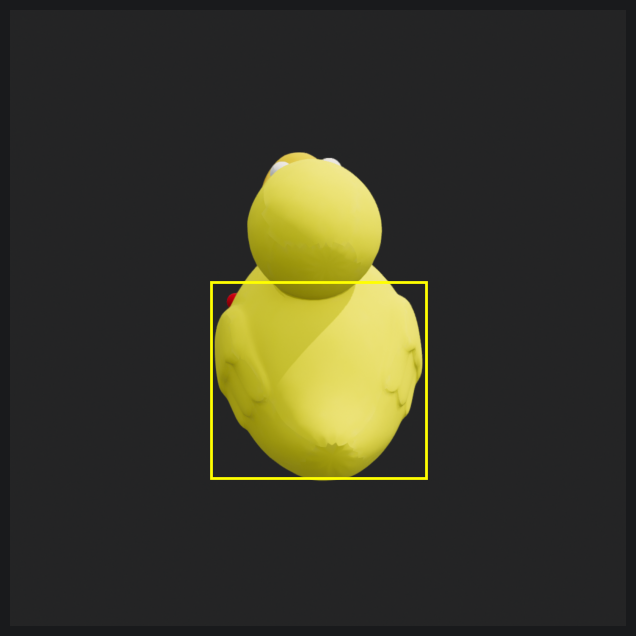

View 004 -> [378, 630, 630, 781]


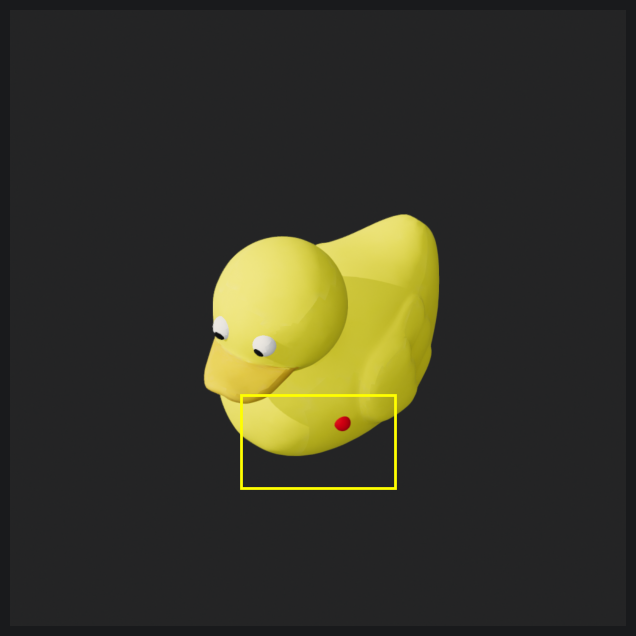

View 005 -> [302, 302, 605, 605]


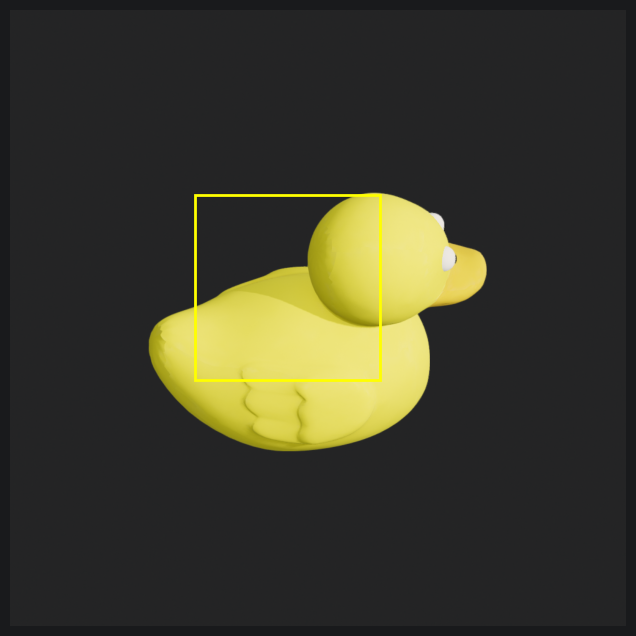

View 006 -> [323, 544, 504, 706]


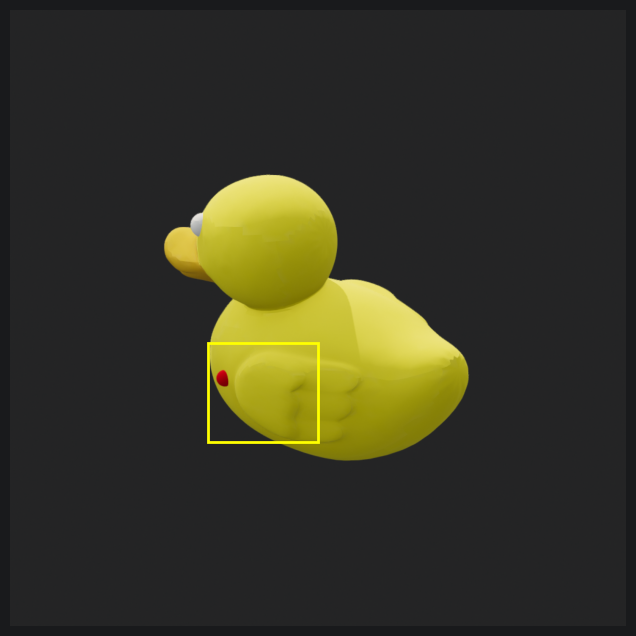

View 007 -> [328, 580, 680, 756]


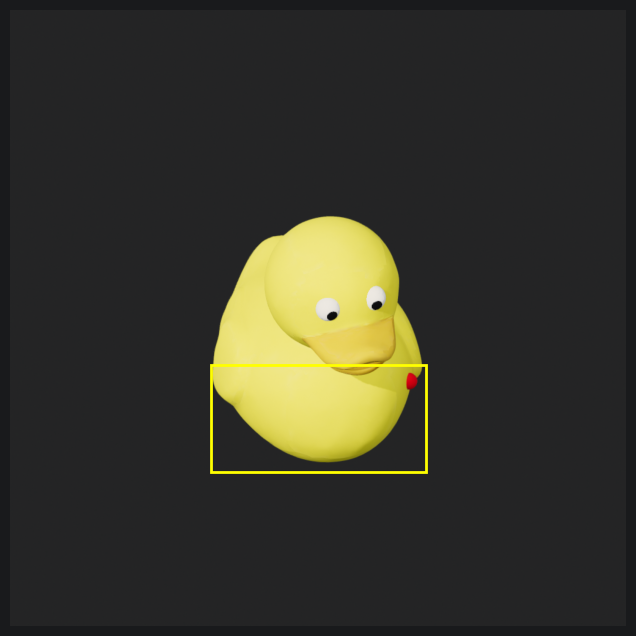

View 008 -> [328, 454, 680, 756]


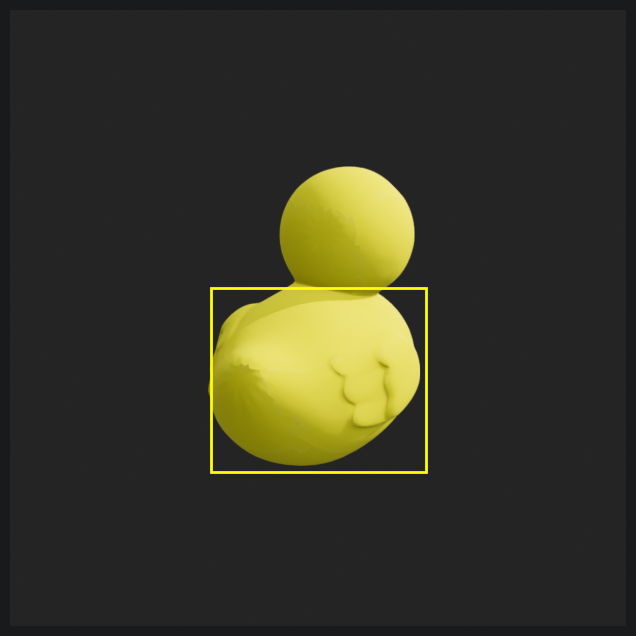

View 009 -> [328, 585, 605, 756]


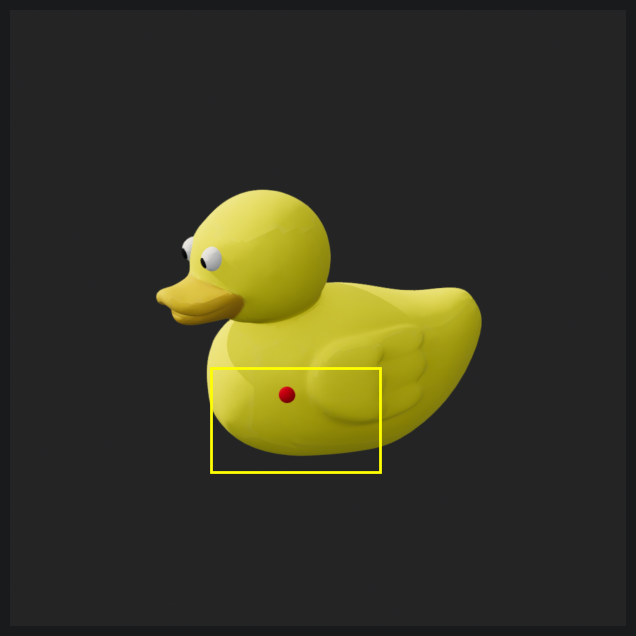

View 010 -> [252, 454, 554, 706]


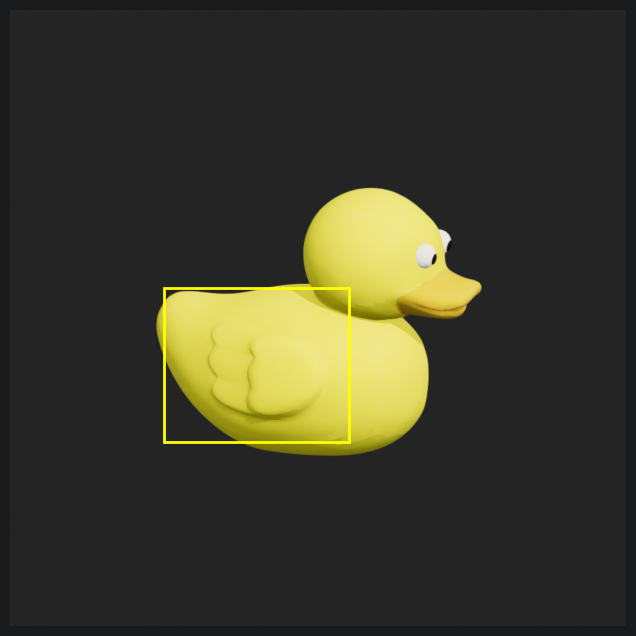

View 011 -> [323, 504, 685, 756]


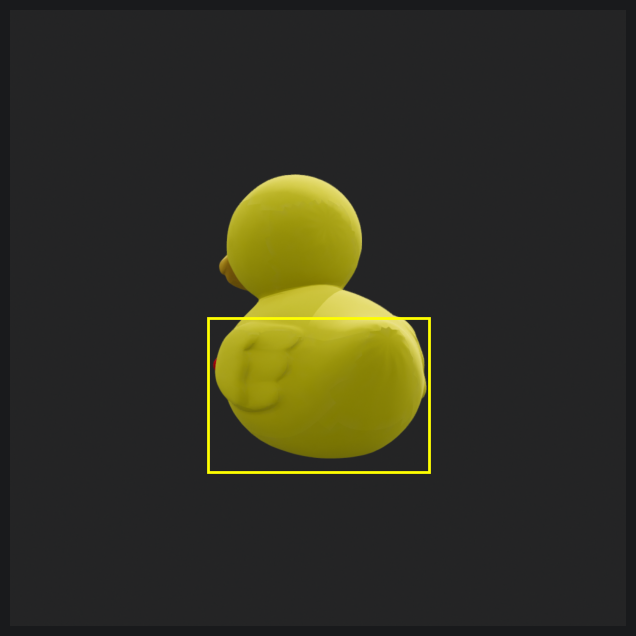

View 012 -> [328, 554, 680, 756]


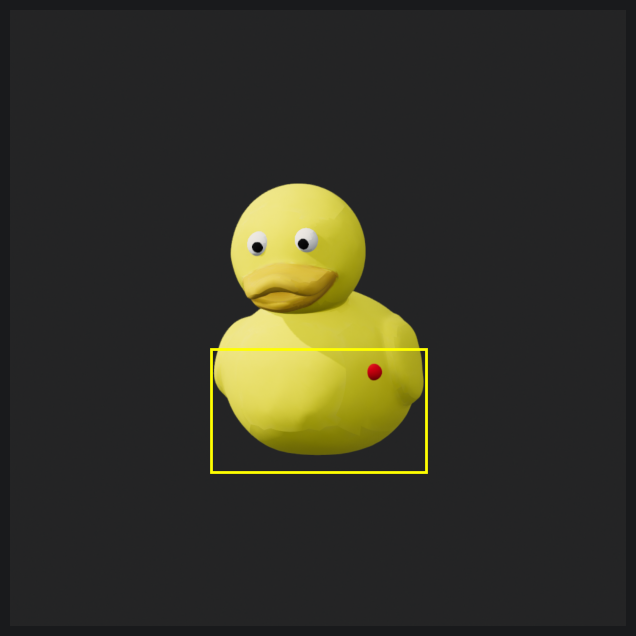

View 013 -> [302, 454, 605, 706]


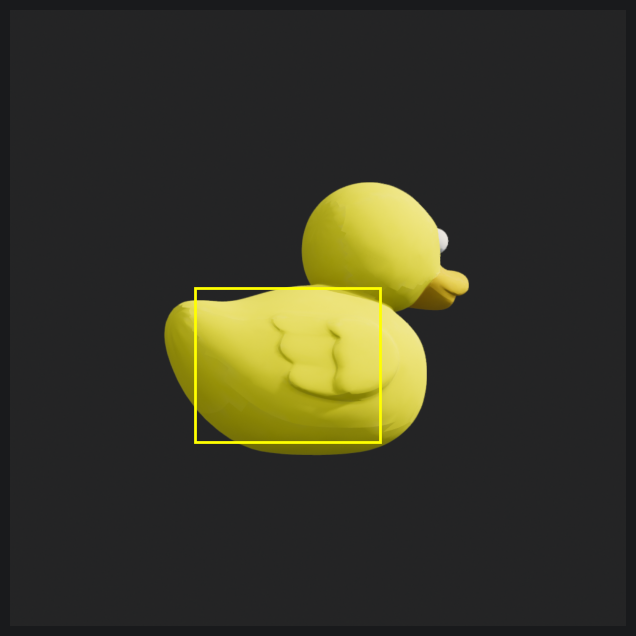

View 014 -> [312, 534, 444, 685]


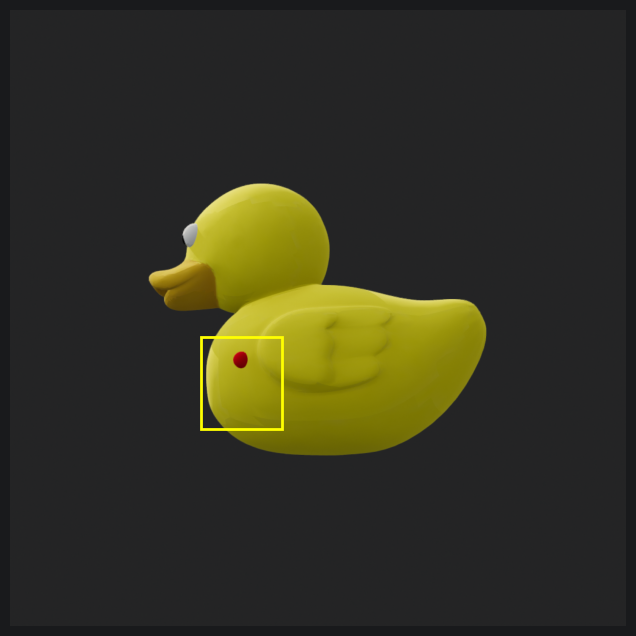

View 015 -> [302, 554, 655, 756]


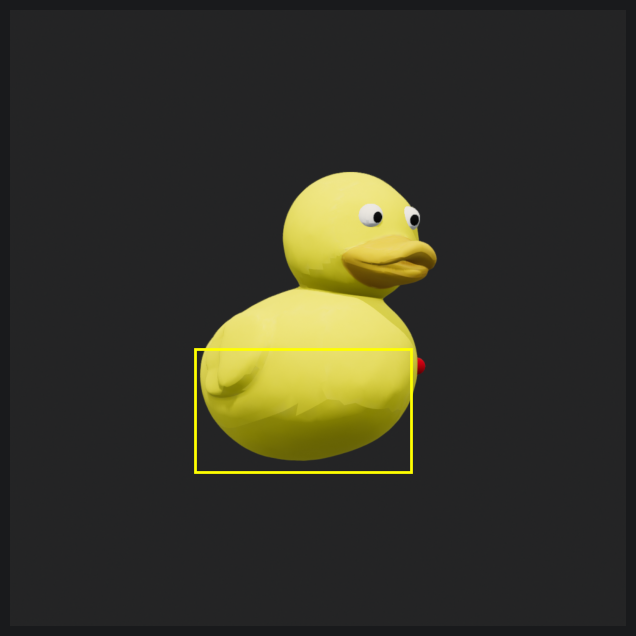

View 016 -> [328, 302, 680, 736]


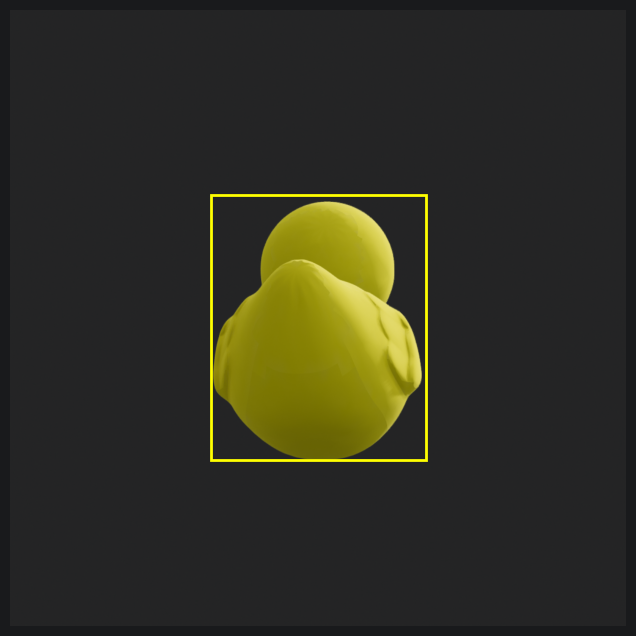

View 017 -> [328, 479, 680, 741]


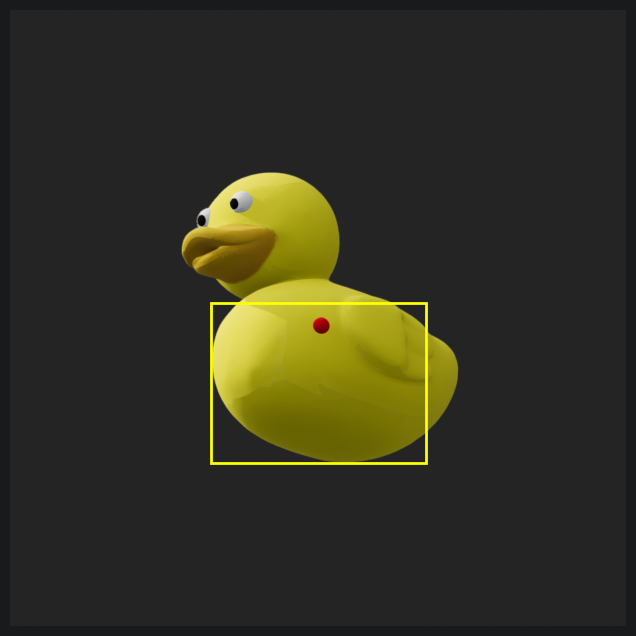

View 018 -> [302, 302, 605, 605]


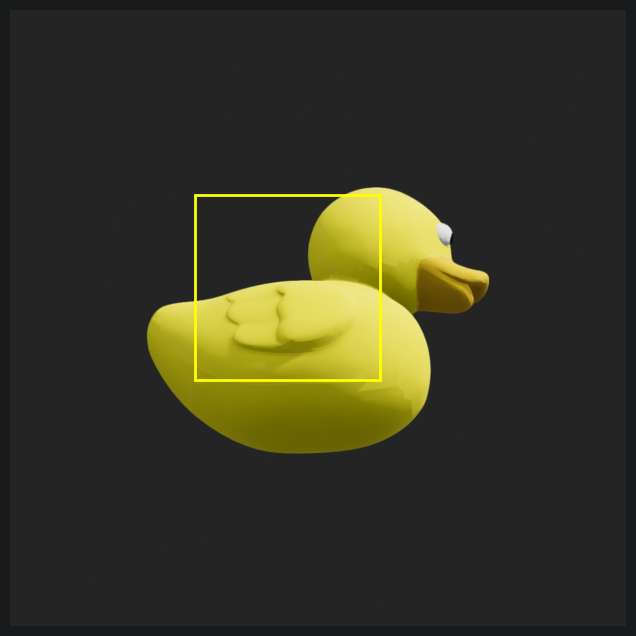

View 019 -> [282, 484, 403, 605]


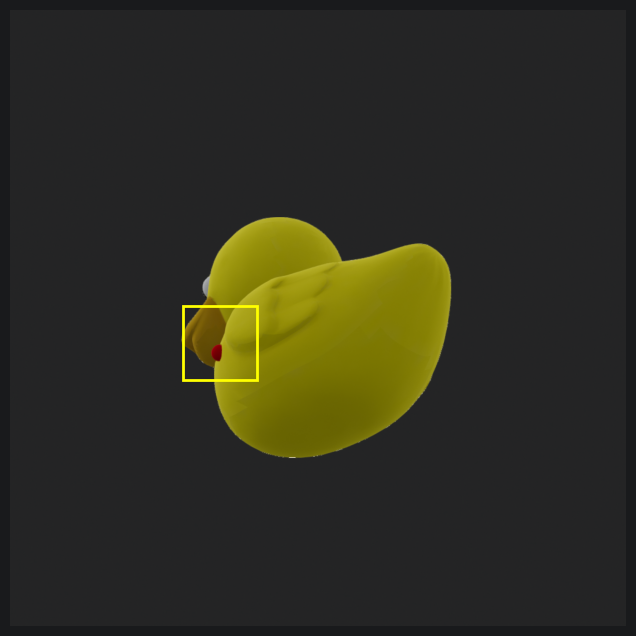

View 020 -> [328, 479, 680, 756]


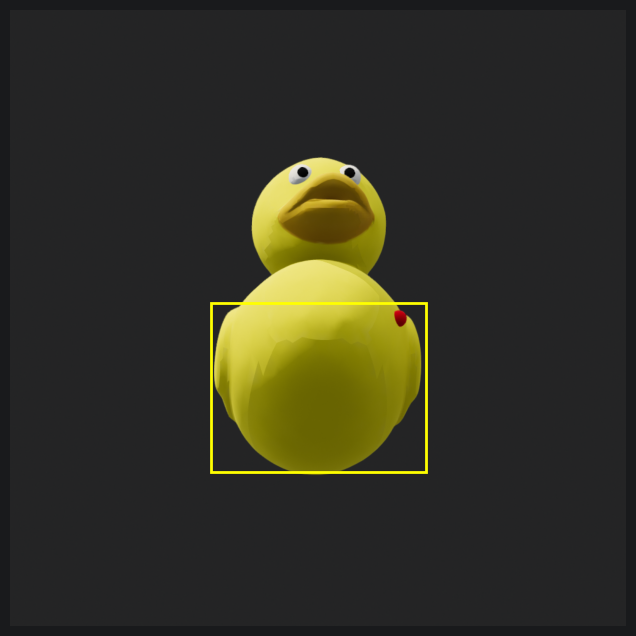

View 021 -> [302, 333, 685, 726]


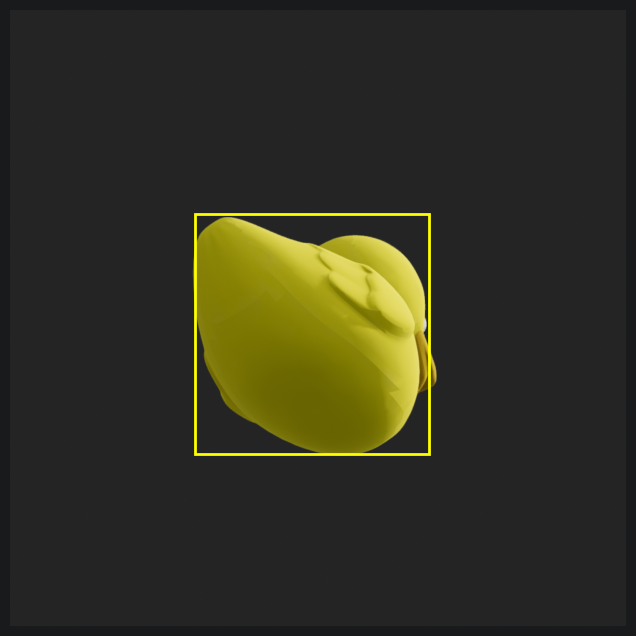

View 022 -> [312, 393, 605, 706]


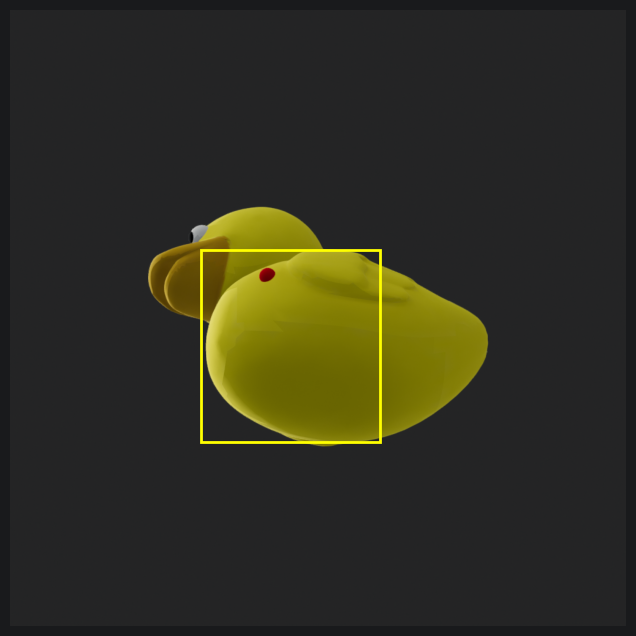

View 023 -> [252, 554, 655, 756]


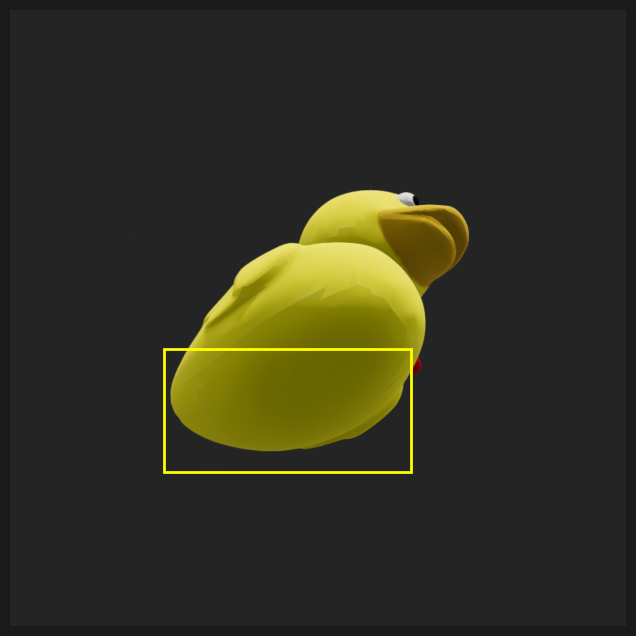

View 024 -> [328, 383, 680, 786]


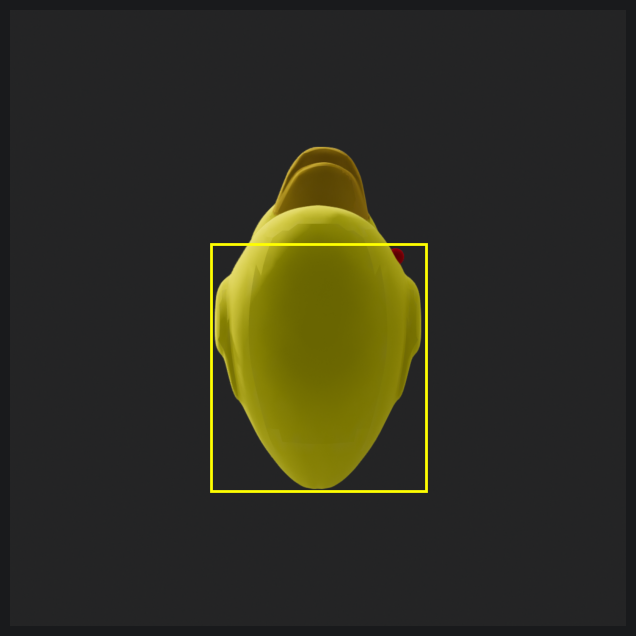

In [40]:
valid_bbox_results = [r for r in bbox_results if r["is_found"]]
print(f"Valid bbox predictions: {len(valid_bbox_results)}/{len(bbox_results)}")

for result in valid_bbox_results:
    print(f"View {result['view_idx'] + 1:03d} -> {result['bbox_2d']}")
    visualize_bbox_result(result["image_path"], result)



In [41]:
def generate_relative_insertion_bbox(
    ollama_host,
    image_path,
    reference_images,
    anchor_2d,
    user_prompt,
    model_name="qwen3-vl:8b-instruct"
):
    with Image.open(image_path) as image:
        width, height = image.size

    ax, ay = anchor_2d

    nx = round(ax / width * 1000)
    ny = round(ay / height * 1000)

    content = f"""
    User request: {user_prompt}

    Attachment anchor in Image 1:
    x = {nx}
    y = {ny}

    Predict the absolute bounding box coordinates
    of the imagined inserted component.
    """

    client = ollama.Client(host=ollama_host)

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": RELATIVE_INSERTION_BBOX_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": content,
                "images": [
                    str(image_path),
                    *[str(p) for p in reference_images]
                ]
            }
        ],
        format="json",
        think=False,
        options={
            "temperature": 0.1,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])

    print("Raw VLM response:", result)

    x1 = result["xmin"] * width / 1000
    y1 = result["ymin"] * height / 1000
    x2 = result["xmax"] * width / 1000
    y2 = result["ymax"] * height / 1000

    bbox = [round(v) for v in [x1, y1, x2, y2]]

    anchor_inside = (
        x1 <= ax <= x2 and
        y1 <= ay <= y2
    )

    print("Anchor inside:", anchor_inside)

    return {
        "is_found": x1 < x2 and y1 < y2,
        "bbox_2d": bbox,
        "anchor_inside": anchor_inside
    }



### 6) Generate voxels and find most important



#### Here we first generate voxel grid, project each voxel on every view with mask. Count the relevance of voxels and keep most important ones



In [42]:
def create_voxel_grid(mesh, resolution=64, padding=0.3):
    """Create a regular voxel grid around the original mesh."""

    extent = mesh.extents.max()
    center = mesh.bounds.mean(axis=0)

    grid_size = extent * (1 + 2 * padding)
    voxel_size = grid_size / resolution

    # Generate voxel center coordinates
    axis = (
        -grid_size / 2
        + (np.arange(resolution) + 0.5) * voxel_size
    )

    x, y, z = np.meshgrid(axis, axis, axis, indexing="ij")

    voxel_points = np.stack(
        [x, y, z], axis=-1
    ).reshape(-1, 3)

    voxel_points += center

    return voxel_points, voxel_size



In [43]:
def project_points_to_image(
    points,
    eye_pos,
    center,
    extent,
    width=1008,
    height=1008,
    frame_scale=1.8,
    up=None
):
    """
    Project 3D points onto an orthographic image.
    """

    half_size = extent / 2 * frame_scale
    aspect = width / height

    # Camera coordinate system
    z_cam = np.asarray(eye_pos) - center
    z_cam /= np.linalg.norm(z_cam)

    if up is None:
        if abs(z_cam[1]) > 0.99:
            up = np.array([
                0., 0., -1. if z_cam[1] > 0 else 1.
            ])
        else:
            up = np.array([0., 1., 0.])

    x_cam = np.cross(up, z_cam)
    x_cam /= np.linalg.norm(x_cam)

    y_cam = np.cross(z_cam, x_cam)

    # Project points onto camera axes
    relative_points = points - center

    x_proj = relative_points @ x_cam
    y_proj = relative_points @ y_cam

    # Convert to pixel coordinates
    px = (
        (x_proj / (half_size * aspect) + 1)
        * width / 2 - 0.5
    )

    py = (
        (1 - y_proj / half_size)
        * height / 2 - 0.5
    )

    return np.column_stack([px, py])



In [44]:
def vote_for_voxels(
    voxel_points,
    bbox_results,
    center,
    extent,
    width=1008,
    height=1008,
    frame_scale=1.8
):
    """Calculate multi-view support for each voxel."""

    votes = np.zeros(len(voxel_points), dtype=np.int32)

    valid_results = [
        result for result in bbox_results
        if result["is_found"]
        and result["bbox_2d"] is not None
    ]

    if not valid_results:
        raise ValueError("No valid bounding boxes")

    for result in valid_results:

        projected = project_points_to_image(
            points=voxel_points,
            eye_pos=result["eye_pos"],
            center=center,
            extent=extent,
            width=width,
            height=height,
            frame_scale=frame_scale,
            up=result.get("up")
        )

        px = projected[:, 0]
        py = projected[:, 1]

        x1, y1, x2, y2 = result["bbox_2d"]

        # Check whether projected voxels are inside the box
        inside = (
            (px >= x1) &
            (px <= x2) &
            (py >= y1) &
            (py <= y2)
        )

        votes += inside.astype(np.int32)

    scores = votes / len(valid_results)

    return scores



In [45]:
base_mesh = _convert_trimesh_to_o3d(mesh)

marker = o3d.geometry.TriangleMesh.create_sphere(
    radius=base_mesh.get_axis_aligned_bounding_box()
                    .get_max_extent() * 0.025
)

marker.translate(anchor_point)

render_bbox = (
    base_mesh + marker
).get_axis_aligned_bounding_box()

render_center = render_bbox.get_center()
render_extent = render_bbox.get_max_extent()

# Restore the original camera up vectors
base_center = base_mesh.get_axis_aligned_bounding_box().get_center()

for result in bbox_results:
    result["up"] = _auto_camera_up(
        base_center,
        result["eye_pos"]
    )



In [46]:
voxel_points, voxel_size = create_voxel_grid(
    mesh,
    resolution=64,
    padding=0.3
)

voxel_scores = vote_for_voxels(
    voxel_points=voxel_points,
    bbox_results=bbox_results,
    center=render_center,
    extent=render_extent,
    frame_scale=1.8
)

print("Total voxels:", len(voxel_points))
print("Maximum score:", voxel_scores.max())



Total voxels: 262144
Maximum score: 0.9166666666666666


In [47]:
threshold = 0.7

selected_voxels = voxel_points[
    voxel_scores >= threshold
]

print("Selected voxels:", len(selected_voxels))



Selected voxels: 3125


In [48]:
def visualize_voxel_grid(mesh, voxel_points, anchor_point):
    """Visualize selected voxel centers and the attachment point."""

    cloud = trimesh.points.PointCloud(
        vertices=voxel_points,
        colors=[255, 0, 0, 255]
    )

    marker = trimesh.creation.icosphere(
        radius=mesh.extents.max() * 0.025
    )

    marker.apply_translation(anchor_point)
    marker.visual.face_colors = [255, 0, 0, 255]

    scene = trimesh.Scene([mesh, cloud, marker])
    return scene



In [49]:
visualize_voxel_grid(
    mesh,
    selected_voxels,
    anchor_point
).show()



In [50]:
for threshold in [0.5, 0.6, 0.75, 0.9]:
    count = np.sum(voxel_scores >= threshold)

    print(f"Threshold {threshold}: {count} voxels")



Threshold 0.5: 11504 voxels
Threshold 0.6: 6405 voxels
Threshold 0.75: 1799 voxels
Threshold 0.9: 1 voxels


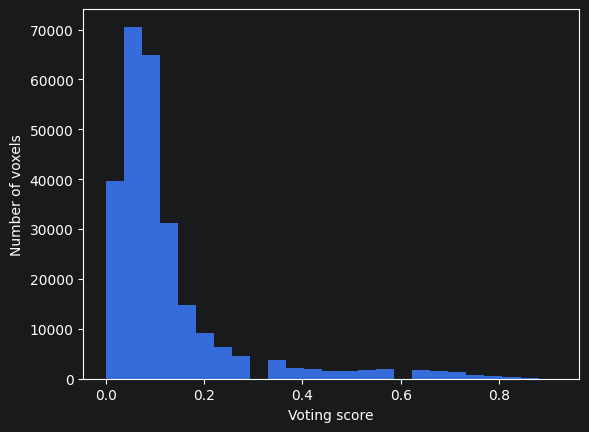

In [51]:
plt.hist(voxel_scores, bins=25)
plt.xlabel("Voting score")
plt.ylabel("Number of voxels")
plt.show()



In [52]:
def is_anchor_visible(image_path, anchor_2d, radius=30):
    image = np.array(
        Image.open(image_path).convert("RGB"),
        dtype=np.float32
    )

    height, width = image.shape[:2]
    x, y = np.round(anchor_2d).astype(int)

    if not (0 <= x < width and 0 <= y < height):
        return False

    region = image[
        max(0, y-radius):min(height, y+radius+1),
        max(0, x-radius):min(width, x+radius+1)
    ]

    red = (
        (region[:, :, 0] > 100) &
        (region[:, :, 0] > region[:, :, 1] * 1.5) &
        (region[:, :, 0] > region[:, :, 2] * 1.5)
    )

    return np.sum(red) > 10



Raw VLM response: {'xmin': 500, 'ymin': 500, 'xmax': 750, 'ymax': 750}
Anchor inside: True
View 001: [504, 504, 756, 756]


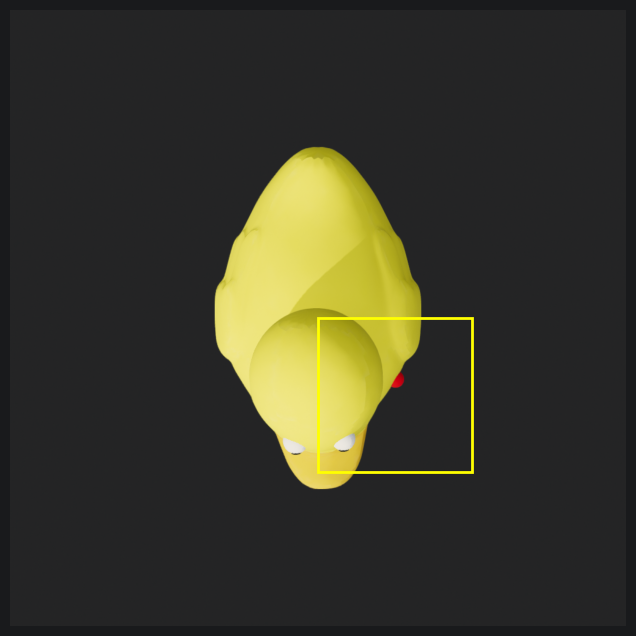

View 002: Anchor not visible
Raw VLM response: {'xmin': 300, 'ymin': 350, 'xmax': 430, 'ymax': 550}
Anchor inside: True
View 003: [302, 353, 433, 554]


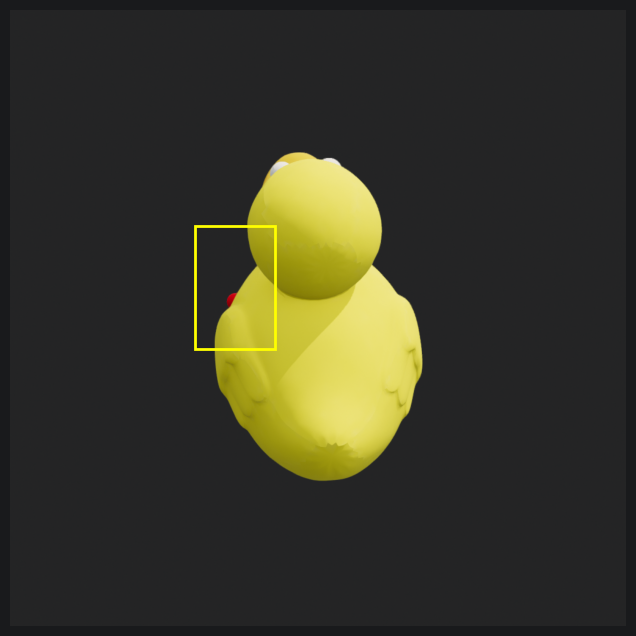

Raw VLM response: {'xmin': 480, 'ymin': 580, 'xmax': 680, 'ymax': 780}
Anchor inside: True
View 004: [484, 585, 685, 786]


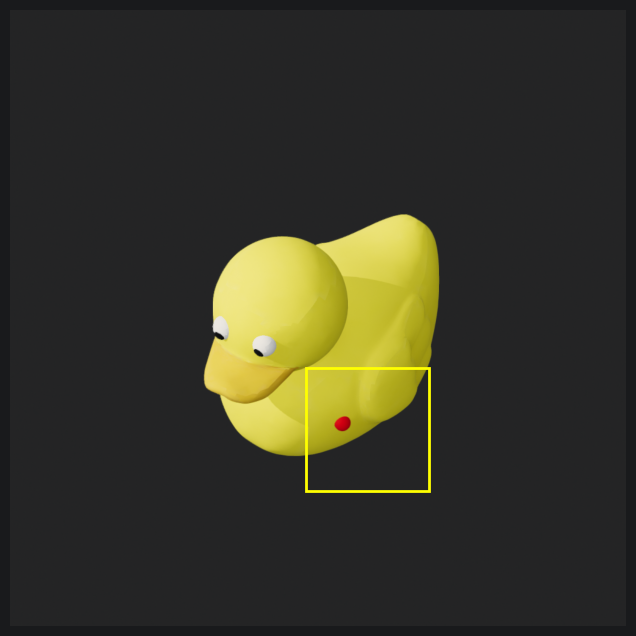

View 005: Anchor not visible
Raw VLM response: {'xmin': 280, 'ymin': 500, 'xmax': 450, 'ymax': 700}
Anchor inside: True
View 006: [282, 504, 454, 706]


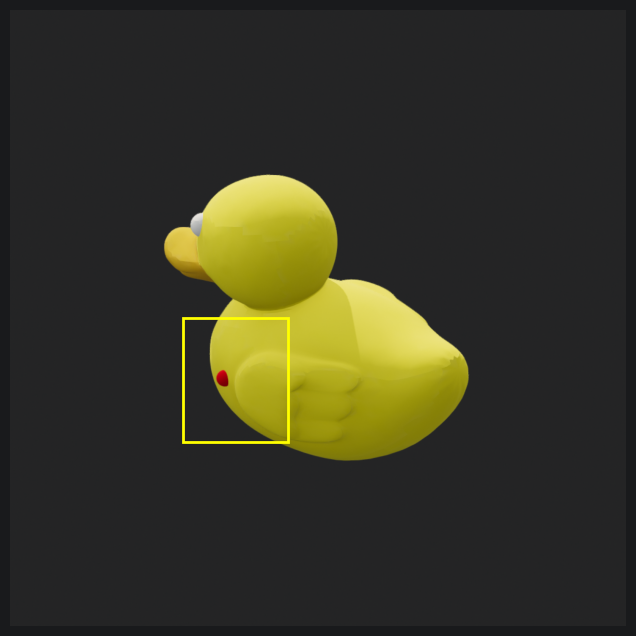

Raw VLM response: {'xmin': 500, 'ymin': 450, 'xmax': 750, 'ymax': 700}
Anchor inside: True
View 007: [504, 454, 756, 706]


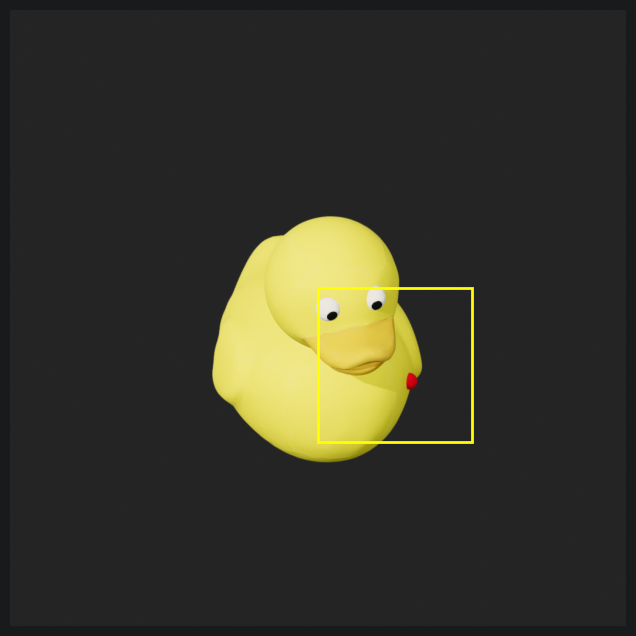

View 008: Anchor not visible
Raw VLM response: {'xmin': 350, 'ymin': 500, 'xmax': 550, 'ymax': 700}
Anchor inside: True
View 009: [353, 504, 554, 706]


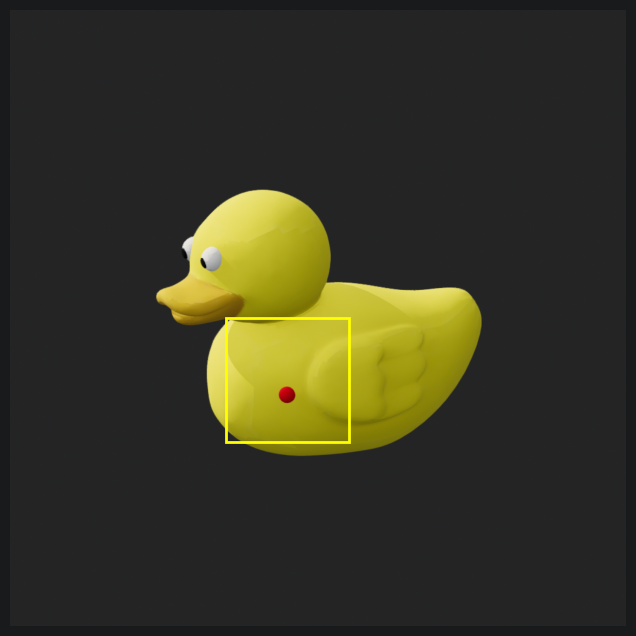

View 010: Anchor not visible
Raw VLM response: {'xmin': 280, 'ymin': 480, 'xmax': 600, 'ymax': 720}
Anchor inside: True
View 011: [282, 484, 605, 726]


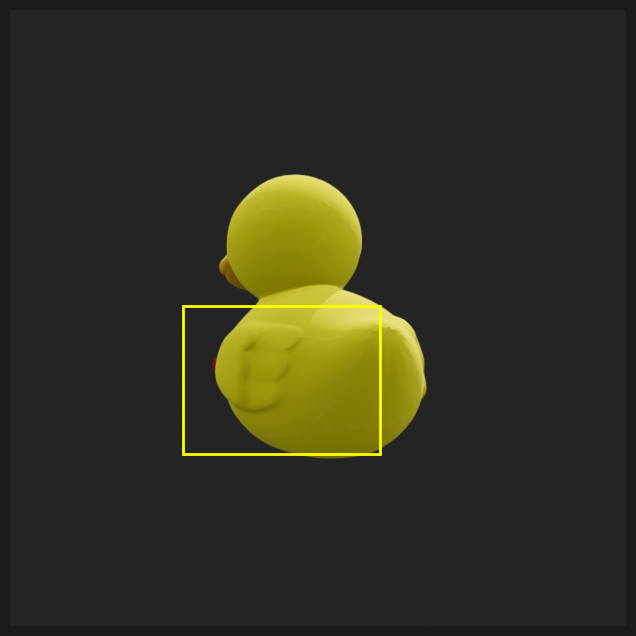

Raw VLM response: {'xmin': 480, 'ymin': 480, 'xmax': 700, 'ymax': 700}
Anchor inside: True
View 012: [484, 484, 706, 706]


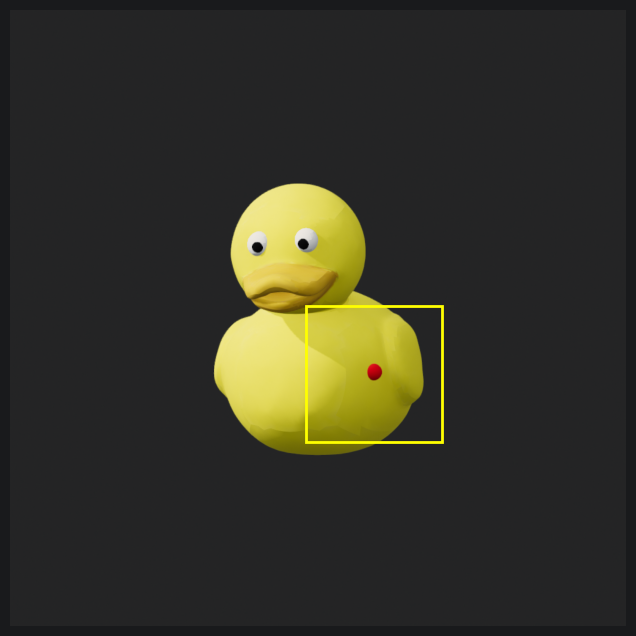

View 013: Anchor not visible
Raw VLM response: {'xmin': 250, 'ymin': 400, 'xmax': 500, 'ymax': 700}
Anchor inside: True
View 014: [252, 403, 504, 706]


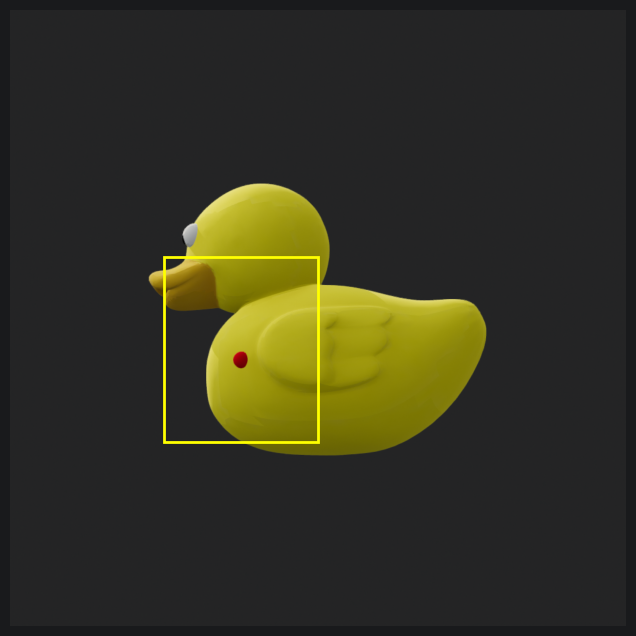

Raw VLM response: {'xmin': 550, 'ymin': 450, 'xmax': 750, 'ymax': 700}
Anchor inside: True
View 015: [554, 454, 756, 706]


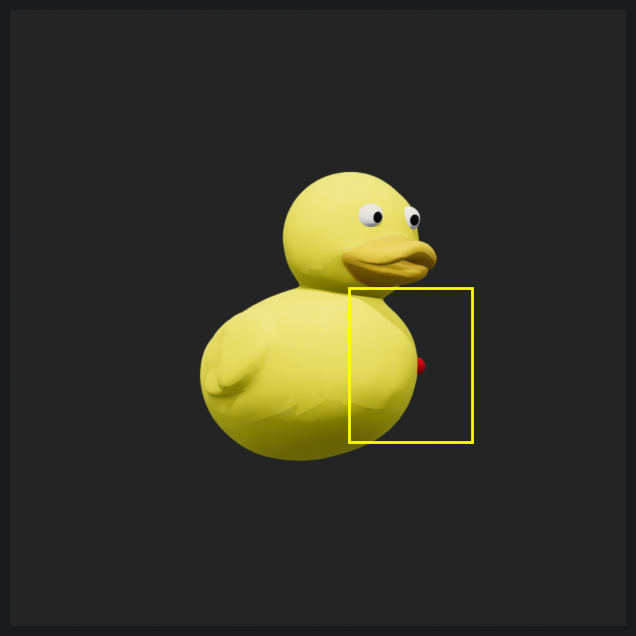

View 016: Anchor not visible
Raw VLM response: {'xmin': 450, 'ymin': 450, 'xmax': 550, 'ymax': 550}
Anchor inside: True
View 017: [454, 454, 554, 554]


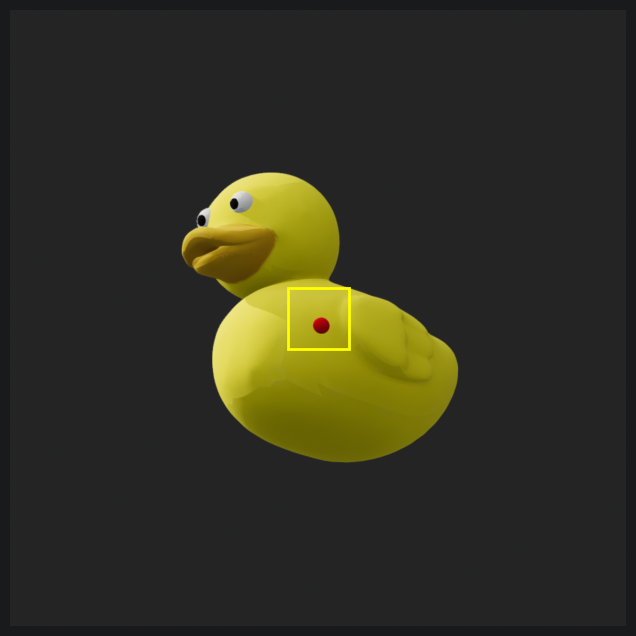

View 018: Anchor not visible
Raw VLM response: {'xmin': 280, 'ymin': 480, 'xmax': 500, 'ymax': 720}
Anchor inside: True
View 019: [282, 484, 504, 726]


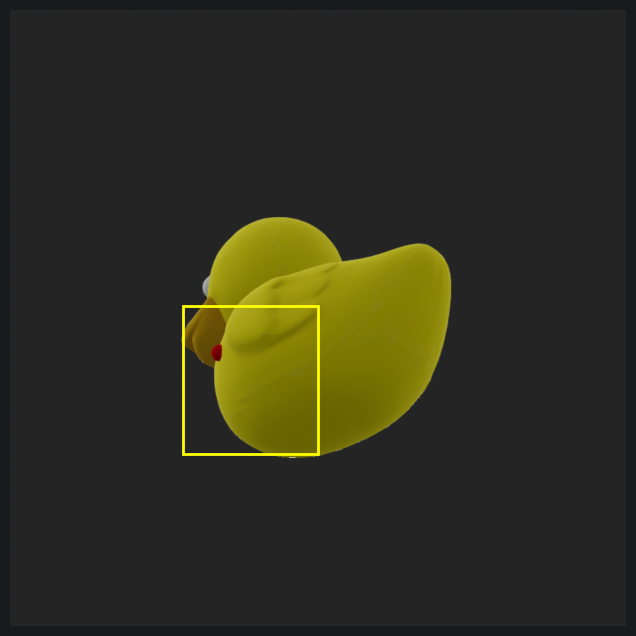

Raw VLM response: {'xmin': 500, 'ymin': 400, 'xmax': 700, 'ymax': 600}
Anchor inside: True
View 020: [504, 403, 706, 605]


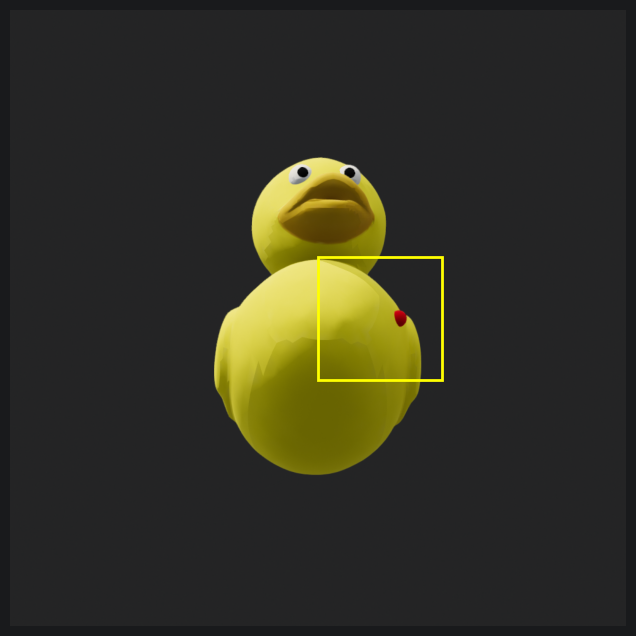

View 021: Anchor not visible
Raw VLM response: {'xmin': 350, 'ymin': 350, 'xmax': 500, 'ymax': 550}
Anchor inside: True
View 022: [353, 353, 504, 554]


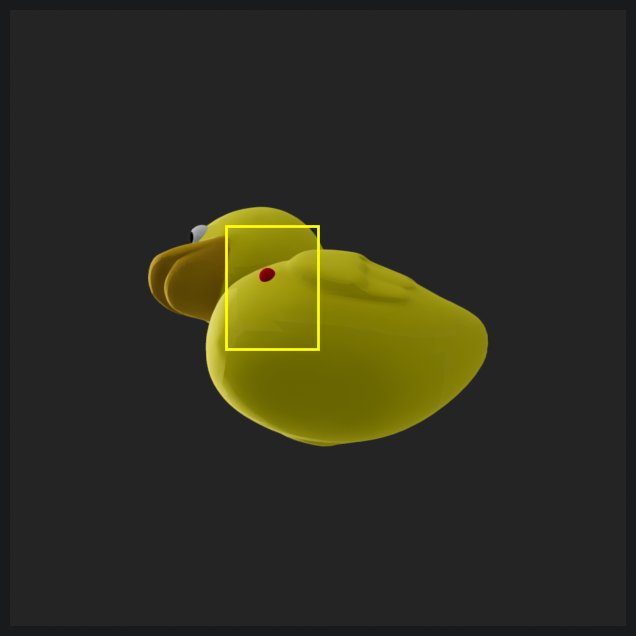

Raw VLM response: {'xmin': 550, 'ymin': 450, 'xmax': 750, 'ymax': 700}
Anchor inside: True
View 023: [554, 454, 756, 706]


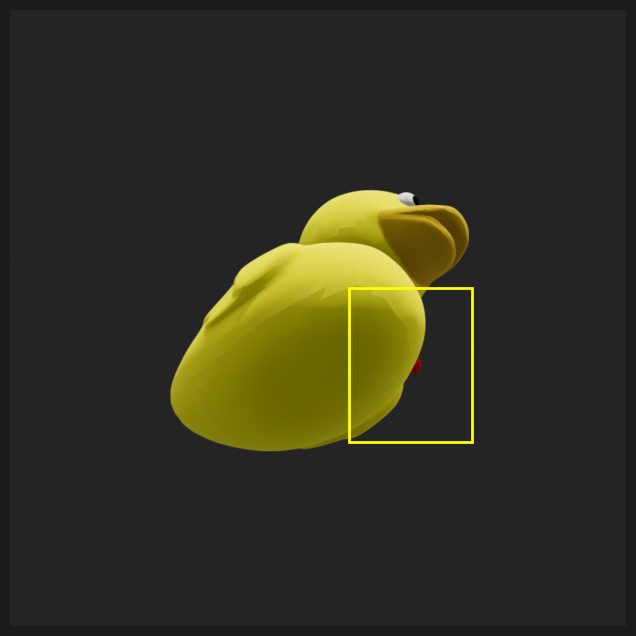

Raw VLM response: {'xmin': 450, 'ymin': 300, 'xmax': 700, 'ymax': 600}
Anchor inside: True
View 024: [454, 302, 706, 605]


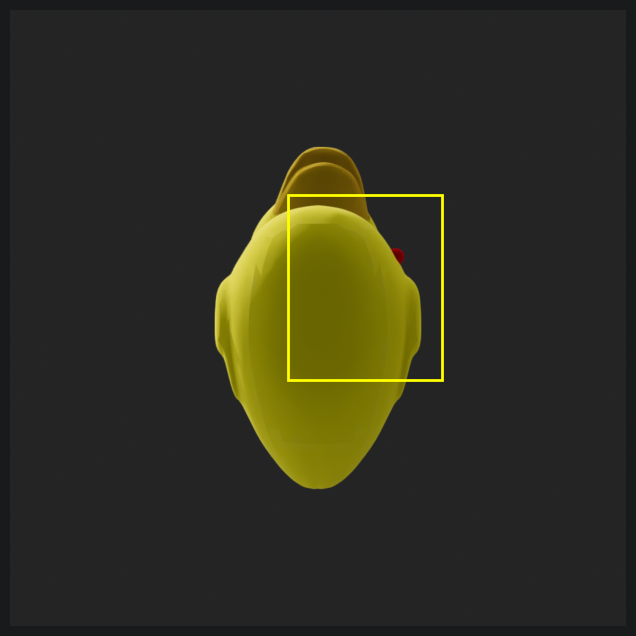

Processed views: 16/24


In [53]:
relative_bbox_results = []

for i, (eye_pos, image_path) in enumerate(anchor_rendered_info):

    camera_up = _auto_camera_up(base_center, eye_pos)

    anchor_2d = project_points_to_image(
        points=np.array([anchor_point]),
        eye_pos=eye_pos,
        center=render_center,
        extent=render_extent,
        frame_scale=1.8,
        up=camera_up
    )[0]

    # Skip views with an occluded anchor
    if not is_anchor_visible(image_path, anchor_2d):
        print(f"View {i+1:03d}: Anchor not visible")
        continue

    result = generate_relative_insertion_bbox(
        ollama_host="192.168.178.23",
        image_path=image_path,
        reference_images=inserted_object_image_paths,
        anchor_2d=anchor_2d,
        user_prompt="""
        Attach a single car wheel at the anchor.
        The wheel diameter should be approximately
        10% of the duck's total body length.
        """
    )

    result.update({
        "view_idx": i,
        "eye_pos": eye_pos,
        "image_path": image_path,
        "up": camera_up,
        "anchor_2d": anchor_2d
    })

    relative_bbox_results.append(result)

    print(f"View {i+1:03d}: {result['bbox_2d']}")

    visualize_bbox_result(image_path, result)

print(f"Processed views: {len(relative_bbox_results)}/24")



In [54]:
relative_voxel_scores = vote_for_voxels(
    voxel_points=voxel_points,
    bbox_results=relative_bbox_results,
    center=render_center,
    extent=render_extent,
    frame_scale=1.8
)

selected_voxels = voxel_points[
    relative_voxel_scores >= 0.8
]

visualize_voxel_grid(
    mesh,
    selected_voxels,
    anchor_point
).show()



### 7) Mesh fitting



#### Now we have to adjust new object offset, scale and rotation angles replace voxels with it



V'=sRV+t
s - scale
R - rotation vector
t - translation


We use voxel volumes to constraint the possible s, R and t values



In [55]:
def select_fitting_views(
    bbox_results,
    selected_views,
    n_views=3
):
    """Select relevant views for mesh fitting."""

    valid_views = {
        r["view_idx"]: r
        for r in bbox_results
        if r["is_found"]
    }

    fitting_views = [
        valid_views[i]
        for i in selected_views
        if i in valid_views
    ]

    return fitting_views[:n_views]



View 009


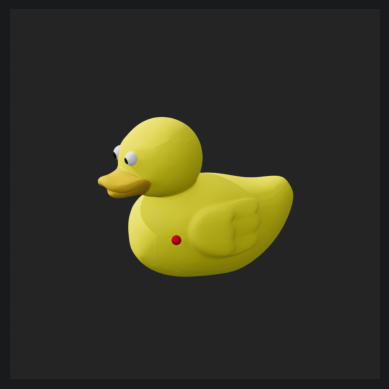

View 017


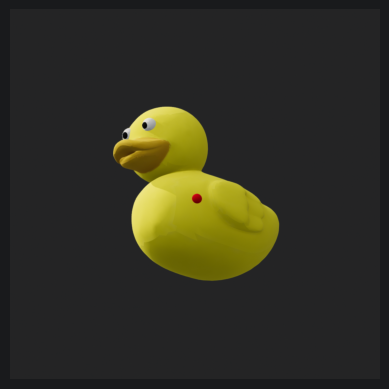

View 012


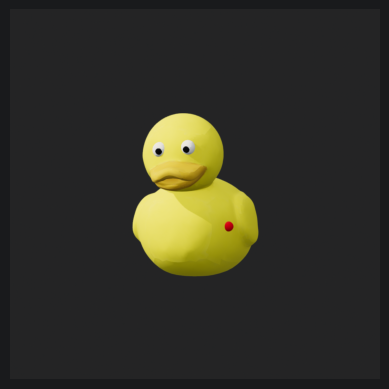

In [56]:
fitting_views = select_fitting_views(
    bbox_results=relative_bbox_results,
    selected_views=selected_views,
    n_views=3
)

for view in fitting_views:
    print(f"View {view['view_idx'] + 1:03d}")

    plt.imshow(Image.open(view["image_path"]))
    plt.axis("off")
    plt.show()



First, we peek the scaling factor since with unsuitable scale factor model is unable to give reasonable results regarding translation and rotation



In [57]:
import os
import json
import math
import copy
import numpy as np
import trimesh
import open3d as o3d

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display


def ensure_trimesh(mesh_like):
    if isinstance(mesh_like, trimesh.Scene):
        return mesh_like.dump(concatenate=True)
    if isinstance(mesh_like, trimesh.Trimesh):
        return mesh_like.copy()
    raise TypeError(f"Unsupported mesh type: {type(mesh_like)}")


def normalize(v, eps=1e-8):
    v = np.asarray(v, dtype=float)
    n = np.linalg.norm(v)
    if n < eps:
        return v
    return v / n


def rotation_matrix_from_vectors(a, b):
    """
    Rotation matrix that rotates vector a onto vector b.
    """
    a = normalize(a)
    b = normalize(b)

    cross = np.cross(a, b)
    dot = np.clip(np.dot(a, b), -1.0, 1.0)

    if np.linalg.norm(cross) < 1e-8:
        if dot > 0:
            return np.eye(3)
        # 180-degree rotation around any orthogonal axis
        ortho = np.array([1.0, 0.0, 0.0])
        if abs(a[0]) > 0.9:
            ortho = np.array([0.0, 1.0, 0.0])
        axis = normalize(np.cross(a, ortho))
        return trimesh.transformations.rotation_matrix(np.pi, axis)[:3, :3]

    s = np.linalg.norm(cross)
    kmat = np.array([
        [0, -cross[2], cross[1]],
        [cross[2], 0, -cross[0]],
        [-cross[1], cross[0], 0]
    ])

    R = np.eye(3) + kmat + kmat @ kmat * ((1 - dot) / (s ** 2))
    return R


def mesh_extents_in_frame(mesh, R):
    """
    Extents of vertices after rotation R.
    """
    verts = mesh.vertices @ R.T
    return verts.max(axis=0) - verts.min(axis=0)



In [58]:
def initialize_scale_transform(
    base_mesh,
    new_object_mesh,
    selected_voxels,
    anchor_point,
    anchor_normal,
    penetration_ratio=0.08
):
    """
    Returns:
        init_scale,
        base_rotation (3x3),
        base_translation (3,),
        attachment_axis_local (3,)
    """
    base_mesh = ensure_trimesh(base_mesh)
    obj_mesh = ensure_trimesh(new_object_mesh)

    voxel_min = selected_voxels.min(axis=0)
    voxel_max = selected_voxels.max(axis=0)
    voxel_extent = voxel_max - voxel_min
    voxel_center = selected_voxels.mean(axis=0)

    # Use PCA-like principal frame from object extents
    obj_extent = obj_mesh.extents
    attachment_axis_idx = np.argmin(obj_extent)   # thinnest axis
    attachment_axis_local = np.eye(3)[attachment_axis_idx]

    # Align thinnest object axis with anchor normal
    normal = normalize(anchor_normal)
    base_rotation = rotation_matrix_from_vectors(
        attachment_axis_local,
        normal
    )

    rotated_extent = mesh_extents_in_frame(obj_mesh, base_rotation)

    # Use voxel support size as initial scale estimate
    # robust scalar: mean of non-small extents
    target_size = np.mean(np.sort(voxel_extent)[-2:])
    source_size = np.mean(np.sort(rotated_extent)[-2:])
    init_scale = float(target_size / max(source_size, 1e-8))

    # Build transformed vertices only for translation estimation
    verts = obj_mesh.vertices @ base_rotation.T
    verts = verts * init_scale

    # Tangential alignment: object center -> voxel cloud center
    obj_center = verts.mean(axis=0)

    normal = normalize(anchor_normal)

    # Shift along normal so object slightly penetrates the mesh
    proj = verts @ normal
    min_proj = proj.min()

    anchor_proj = np.dot(anchor_point, normal)
    penetration = base_mesh.extents.max() * penetration_ratio

    delta_n = (anchor_proj - penetration) - min_proj

    # Tangent-plane alignment using voxel center
    obj_center_tangent = obj_center - np.dot(obj_center, normal) * normal
    voxel_center_tangent = voxel_center - np.dot(voxel_center, normal) * normal
    delta_tangent = voxel_center_tangent - obj_center_tangent

    base_translation = delta_tangent + delta_n * normal

    return init_scale, base_rotation, base_translation, attachment_axis_local




In [59]:
def transform_object_mesh(
    new_object_mesh,
    scale,
    rotation_matrix,
    translation
):
    obj_mesh = ensure_trimesh(new_object_mesh).copy()

    verts = obj_mesh.vertices @ rotation_matrix.T
    verts = verts * scale
    verts = verts + translation

    obj_mesh.vertices = verts
    return obj_mesh



In [60]:
def render_scene_views_with_object(
    base_mesh,
    object_mesh,
    fitting_views,
    output_dir,
    image_size=512,
    frame_scale=1.8
):
    os.makedirs(output_dir, exist_ok=True)

    base_o3d = _convert_trimesh_to_o3d(ensure_trimesh(base_mesh), is_objaverse_model=False)
    obj_o3d = _convert_trimesh_to_o3d(ensure_trimesh(object_mesh), is_objaverse_model=False)

    bbox = base_o3d.get_axis_aligned_bounding_box()
    center = bbox.get_center()
    extent = bbox.get_max_extent()

    half_size = (extent / 2.0) * frame_scale
    aspect = 1.0

    renderer = o3d.visualization.rendering.OffscreenRenderer(image_size, image_size)

    material_base = o3d.visualization.rendering.MaterialRecord()
    material_base.shader = "defaultLit"

    material_obj = o3d.visualization.rendering.MaterialRecord()
    material_obj.shader = "defaultLit"

    renderer.scene.add_geometry("base_mesh", base_o3d, material_base)
    renderer.scene.add_geometry("inserted_mesh", obj_o3d, material_obj)
    renderer.scene.set_background(np.array([0.2, 0.2, 0.2, 1.0]))

    rendered_paths = []

    for local_idx, view in enumerate(fitting_views):
        eye = np.asarray(view["eye_pos"], dtype=float)
        up = np.asarray(view["up"], dtype=float)

        renderer.scene.camera.look_at(center, eye, up)
        renderer.scene.camera.set_projection(
            o3d.visualization.rendering.Camera.Projection.Ortho,
            -half_size * aspect, half_size * aspect,
            -half_size, half_size,
            0.1, extent * 10.0
        )

        img = renderer.render_to_image()
        path = os.path.join(output_dir, f"view_{local_idx:02d}.png")
        o3d.io.write_image(path, img)
        rendered_paths.append(path)

    del renderer
    return rendered_paths


def build_candidate_collage(image_paths, out_path):
    images = [Image.open(p).convert("RGB") for p in image_paths]

    w, h = images[0].size
    header_h = 40
    canvas = Image.new("RGB", (w * len(images), h + header_h), "white")
    draw = ImageDraw.Draw(canvas)

    for i, img in enumerate(images):
        canvas.paste(img, (i * w, header_h))
        draw.text((i * w + 10, 10), f"View {i+1}", fill="black")

    canvas.save(out_path)
    return out_path



In [61]:
def build_candidates_grid(collage_paths, out_path, columns=2):
    collages = [Image.open(p).convert("RGB") for p in collage_paths]

    w, h = collages[0].size
    rows = math.ceil(len(collages) / columns)

    canvas = Image.new("RGB", (columns * w, rows * h), "white")

    for idx, img in enumerate(collages):
        x = (idx % columns) * w
        y = (idx // columns) * h
        canvas.paste(img, (x, y))

    canvas.save(out_path)
    return out_path



In [62]:
def generate_scale_candidates(center_scale, radius=0.4, n=5):
    """
    Example:
    center=1.0, radius=0.4, n=5
    -> [0.6, 0.8, 1.0, 1.2, 1.4]
    """
    offsets = np.linspace(-radius, radius, n)
    candidates = [center_scale * (1.0 + o) for o in offsets]
    return [float(max(1e-4, c)) for c in candidates]



In [63]:
import ollama

SCALE_SELECTION_SYSTEM_PROMPT = """
You are evaluating different scales of a component
inserted into a 3D object.

Each input image represents one candidate.
Each image contains different camera views
of the same candidate.

Candidate numbering follows the input image order.

Compare the same camera viewpoints across candidates.

Evaluate:
- The size of the inserted component relative to the base object.
- Natural proportions.
- Consistency with the user request.

Do not prefer larger or more visually prominent components.
Do not judge image quality.
Focus on the relative size of the inserted component.

Return only JSON:
{
    "best_candidate": integer,
    "reason": string
}

Candidate numbering starts from 1.
"""

def select_best_scale_candidate(
    candidate_collage_paths,
    user_prompt,
    ollama_host="192.168.178.23",
    model_name="qwen3-vl:8b-instruct"
):
    client = ollama.Client(host=ollama_host)

    content = f"""
User request:
{user_prompt}

Each image is one candidate.
Candidate numbering follows the order of the provided images:
1, 2, 3, ...

Pick the best scale candidate.
"""

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": SCALE_SELECTION_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": content,
                "images": [str(p) for p in candidate_collage_paths]
            }
        ],
        format="json",
        think=False,
        options={
            "temperature": 0.1,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])
    print("VLM scale selection:", result)
    return result



In [64]:
base_mesh_fit = ensure_trimesh(mesh)
new_object_mesh_fit = ensure_trimesh(new_object_mesh)

init_scale, base_rotation, base_translation, attachment_axis_local = initialize_scale_transform(
    base_mesh=base_mesh_fit,
    new_object_mesh=new_object_mesh_fit,
    selected_voxels=selected_voxels,
    anchor_point=anchor_point,
    anchor_normal=anchor_normal
)

print("Initial scale:", init_scale)
print("Base translation:", base_translation)
print("Base rotation:\n", base_rotation)



Initial scale: 0.41506315482010697
Base translation: [ 0.26577492 -0.06717793  0.2075073 ]
Base rotation:
 [[ 0.4996379  -0.04012031  0.86530476]
 [-0.04012031  0.99678305  0.06938235]
 [-0.86530476 -0.06938235  0.49642095]]


/var/folders/qs/52kg654j54s2yxqv9z1v3l840000gn/T/ipykernel_21163/3422248490.py:16: DeprecationWarning: `Scene.dump(concatenate=True)` DEPRECATED FOR REMOVAL APRIL 2025: replace with `Scene.to_geometry()`
  return mesh_like.dump(concatenate=True)


In [65]:
def run_scale_search(
    base_mesh,
    new_object_mesh,
    fitting_views,
    base_rotation,
    base_translation,
    init_scale,
    user_prompt,
    anchor_point,
    output_root="scale_search",
    n_iterations=3,
    n_candidates=5,
    initial_radius=0.4,
    image_size=512,
):
    os.makedirs(output_root, exist_ok=True)

    current_scale = init_scale
    current_radius = initial_radius

    history = []

    for iteration in range(n_iterations):
        print(f"\n=== Scale iteration {iteration + 1} ===")
        print(f"Center scale: {current_scale:.6f}")
        print(f"Search radius: {current_radius:.6f}")

        iter_dir = os.path.join(output_root, f"iter_{iteration + 1:02d}")
        os.makedirs(iter_dir, exist_ok=True)

        candidate_scales = generate_scale_candidates(
            center_scale=current_scale,
            radius=current_radius,
            n=n_candidates
        )
        random.shuffle(candidate_scales)

        candidate_infos = []
        collage_paths = []

        for cand_idx, scale_value in enumerate(candidate_scales, start=1):
            #candidate_name = f"Candidate {cand_idx} | scale={scale_value:.4f}"

            candidate_translation = (
                anchor_point
                + (scale_value / init_scale)
                * (base_translation - anchor_point)
            )

            transformed_mesh = transform_object_mesh(
                new_object_mesh=new_object_mesh,
                scale=scale_value,
                rotation_matrix=base_rotation,
                translation=candidate_translation
            )

            render_dir = os.path.join(iter_dir, f"candidate_{cand_idx:02d}_views")
            view_paths = render_scene_views_with_object(
                base_mesh=base_mesh,
                object_mesh=transformed_mesh,
                fitting_views=fitting_views,
                output_dir=render_dir,
                image_size=image_size,
                frame_scale=1.8
            )

            collage_path = os.path.join(iter_dir, f"candidate_{cand_idx:02d}_collage.png")
            build_candidate_collage(
                image_paths=view_paths,
                #candidate_name=candidate_name,
                out_path=collage_path
            )

            collage_paths.append(collage_path)

            candidate_infos.append({
                "candidate_idx": cand_idx,
                "scale": scale_value,
                "rotation": base_rotation.copy(),
                "translation": candidate_translation.copy(),
                "mesh": transformed_mesh,
                "view_paths": view_paths,
                "collage_path": collage_path
            })

        # Grid for you
        grid_path = os.path.join(iter_dir, "all_candidates_grid.png")
        build_candidates_grid(
            collage_paths=collage_paths,
            out_path=grid_path,
            columns=2
        )

        print(f"Saved grid: {grid_path}")
        display(Image.open(grid_path))

        # Send the separate collages to VLM
        vlm_result = select_best_scale_candidate(
            candidate_collage_paths=collage_paths,
            user_prompt=user_prompt
        )

        best_idx = int(vlm_result["best_candidate"]) - 1
        if not 0 <= best_idx < len(candidate_infos):
            raise ValueError("Invalid candidate ID")
        best_info = candidate_infos[best_idx]

        print(f"Selected candidate: {best_info['candidate_idx']}")
        print(f"Selected scale: {best_info['scale']:.6f}")

        history.append({
            "iteration": iteration + 1,
            "grid_path": grid_path,
            "vlm_result": vlm_result,
            "candidate_infos": candidate_infos,
            "selected_candidate": best_info
        })

        current_scale = best_info["scale"]
        current_radius *= 0.5

    return history




=== Scale iteration 1 ===
Center scale: 0.415063
Search radius: 0.400000
FEngine (64 bits) created at 0x33c898200 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1
FEngine (64 bits) created at 0x33a5ca600 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1
FEngine (64 bits) created at 0x33c89c200 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature le

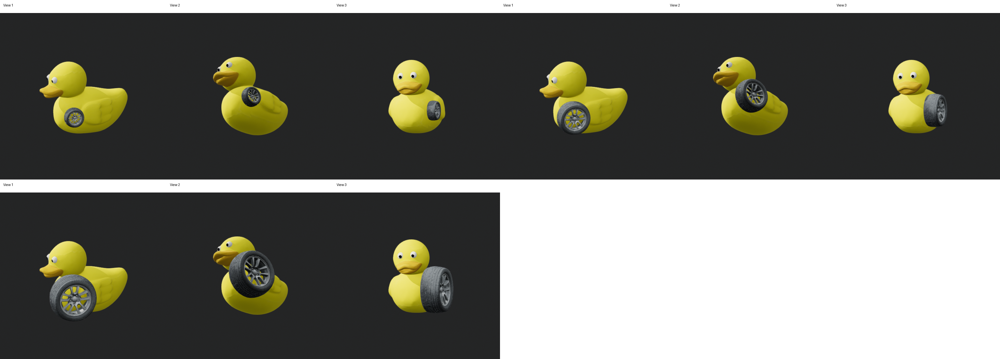

VLM scale selection: {'best_candidate': 3, 'reason': "In candidate 3, the wheel appears to be the most proportionate to the duck's body length, visually matching the 10% size requirement. The wheel is not excessively large or small compared to the duck's overall dimensions across all views."}
Selected candidate: 3
Selected scale: 0.581088

=== Scale iteration 2 ===
Center scale: 0.581088
Search radius: 0.200000
FEngine (64 bits) created at 0x33c503a00 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1
FEngine (64 bits) created at 0x33a5ca600 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend featu

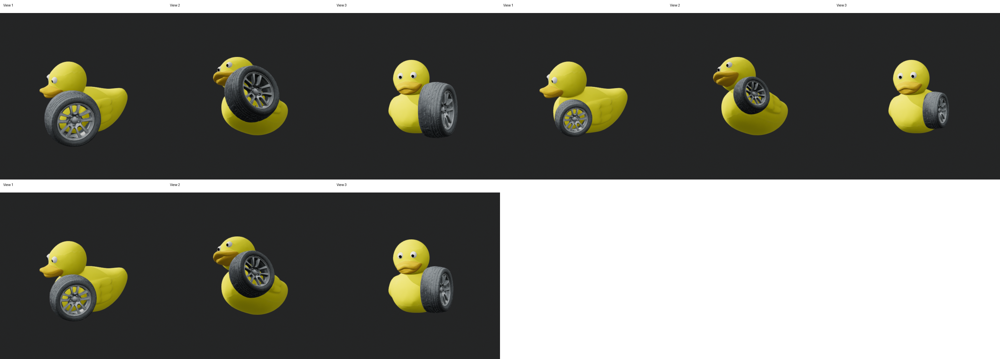

VLM scale selection: {'best_candidate': 1, 'reason': "In View 1, the wheel appears to be approximately 10% of the duck's body length, matching the user's requirement. The other candidates show wheels that are either too large or too small relative to the duck's body."}
Selected candidate: 1
Selected scale: 0.697306

=== Scale iteration 3 ===
Center scale: 0.697306
Search radius: 0.100000
FEngine (64 bits) created at 0x33a5ca600 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1
FEngine (64 bits) created at 0x33c89c200 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feat

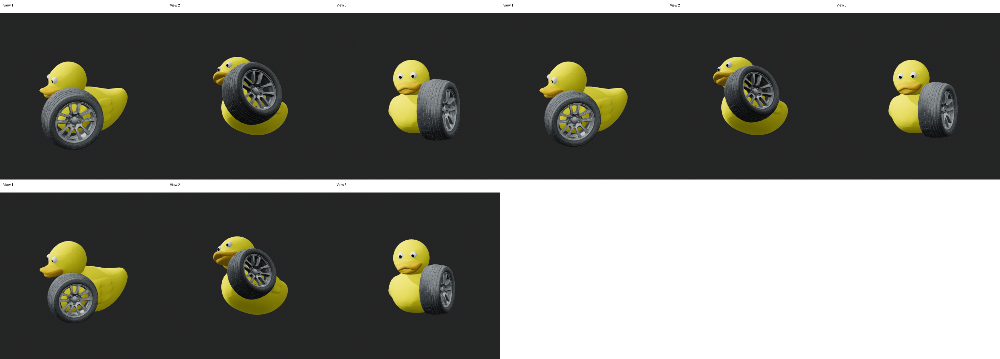

VLM scale selection: {'best_candidate': 1, 'reason': "In View 1, the wheel appears to be approximately 10% of the duck's total body length, which matches the user's requirement. The other candidates show wheels that are either too large or too small relative to the duck's body."}
Selected candidate: 1
Selected scale: 0.767037


In [66]:
scale_history = run_scale_search(
    base_mesh=base_mesh_fit,
    new_object_mesh=new_object_mesh_fit,
    fitting_views=fitting_views,
    base_rotation=base_rotation,
    base_translation=base_translation,
    init_scale=init_scale,
    anchor_point = anchor_point,
    user_prompt = """
        Attach a single car wheel to the duck.

        The wheel diameter should be approximately
        10% of the duck's total body length.

        Select the candidate that best satisfies this requirement.
        """,
    output_root="scale_search",
    n_iterations=3,
    n_candidates=3,
    initial_radius=0.4,
    image_size=512
)



In [ ]:
best_scale_candidate = scale_history[-1]["selected_candidate"]

best_scale = best_scale_candidate["scale"]
best_scale_rotation = best_scale_candidate["rotation"]
best_scale_translation = best_scale_candidate["translation"]
best_scale_mesh = best_scale_candidate["mesh"]

print("Final selected scale:", best_scale)

scene = trimesh.Scene([
    base_mesh_fit,
    best_scale_mesh
])

scene.show()

Now we should pick the rotation angle.



In [68]:
ROTATION_SELECTION_SYSTEM_PROMPT = """
You are evaluating different orientations of a component
inserted into a 3D object.

Each input image represents one candidate.
Each image contains three different camera viewpoints.

Compare the same camera viewpoints across candidates.

Evaluate:
- The orientation of the inserted component
  relative to the base object.
- Natural alignment.
- Consistency with the user request.

Do not prefer larger or more visually prominent components.
Do not judge image quality.
Focus on the relative orientation of the inserted component.

Return only JSON:
{
    "best_candidate": integer,
    "reason": string
}

Candidate numbering starts from 1.
"""


In [69]:
def generate_rotation_candidates(
    current_rotation,
    current_translation,
    anchor_point,
    axis,
    angle_step
):
    candidates = []

    for angle in [-angle_step, 0, angle_step]:

        delta_rotation = trimesh.transformations.rotation_matrix(
            np.deg2rad(angle),
            axis
        )[:3, :3]

        rotation = delta_rotation @ current_rotation

        translation = (
            anchor_point
            + delta_rotation @ (current_translation - anchor_point)
        )

        candidates.append({
            "angle": angle,
            "rotation": rotation,
            "translation": translation
        })

    random.shuffle(candidates)

    return candidates



In [70]:
def select_best_rotation_candidate(
    candidate_collage_paths,
    user_prompt,
    ollama_host="192.168.178.23",
    model_name="qwen3-vl:8b-instruct"
):
    client = ollama.Client(host=ollama_host)

    content = f"""
    User request:
    {user_prompt}

    Each image is one candidate.
    Candidate numbering follows the order of the provided images:
    1, 2, 3, ...

    Pick the best rotation candidate.
    """

    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": ROTATION_SELECTION_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": content,
                "images": [str(p) for p in candidate_collage_paths]
            }
        ],
        format="json",
        think=False,
        options={
            "temperature": 0.1,
            "num_ctx": 16384
        }
    )

    result = json.loads(response["message"]["content"])
    print("VLM rotation selection:", result)

    return result


In [71]:
def run_rotation_search(
    base_mesh,
    new_object_mesh,
    fitting_views,
    anchor_point,
    best_scale,
    base_rotation,
    base_translation,
    user_prompt,
    output_root="rotation_search",
    n_iterations=3,
    initial_angle_step=45,
    image_size=512
):
    current_rotation = base_rotation.copy()
    current_translation = base_translation.copy()
    angle_step = initial_angle_step

    axes = {
        "X": np.array([1., 0., 0.]),
        "Y": np.array([0., 1., 0.]),
        "Z": np.array([0., 0., 1.])
    }

    history = []

    for iteration in range(n_iterations):

        for axis_name, axis in axes.items():

            print(f"\n=== Rotation iteration {iteration+1} ===")
            print(f"Axis: {axis_name}")
            print(f"Angle step: {angle_step:.2f}")

            iter_dir = os.path.join(
                output_root,
                f"iter_{iteration+1:02d}_{axis_name}"
            )

            os.makedirs(iter_dir, exist_ok=True)

            candidates = generate_rotation_candidates(
                current_rotation=current_rotation,
                current_translation=current_translation,
                anchor_point=anchor_point,
                axis=axis,
                angle_step=angle_step
            )

            collage_paths = []

            for i, candidate in enumerate(candidates, start=1):

                transformed_mesh = transform_object_mesh(
                    new_object_mesh=new_object_mesh,
                    scale=best_scale,
                    rotation_matrix=candidate["rotation"],
                    translation=candidate["translation"]
                )

                view_paths = render_scene_views_with_object(
                    base_mesh=base_mesh,
                    object_mesh=transformed_mesh,
                    fitting_views=fitting_views,
                    output_dir=os.path.join(
                        iter_dir, f"candidate_{i:02d}"
                    ),
                    image_size=image_size,
                    frame_scale=1.8
                )

                collage_path = os.path.join(
                    iter_dir,
                    f"candidate_{i:02d}.png"
                )

                build_candidate_collage(
                    image_paths=view_paths,
                    out_path=collage_path
                )

                # Label the candidate
                with Image.open(collage_path) as img:
                    collage = img.convert("RGB")

                draw = ImageDraw.Draw(collage)
                draw.rectangle(
                    (0, 0, collage.width, 39),
                    fill="white"
                )
                draw.text(
                    (10, 10),
                    f"Candidate {i}",
                    fill="black"
                )

                collage.save(collage_path)

                collage_paths.append(collage_path)

                candidate["mesh"] = transformed_mesh

            grid_path = os.path.join(
                iter_dir, "all_candidates_grid.png"
            )

            build_candidates_grid(
                collage_paths=collage_paths,
                out_path=grid_path,
                columns=1
            )

            display(Image.open(grid_path))

            result = select_best_rotation_candidate(
                candidate_collage_paths=collage_paths,
                user_prompt=user_prompt
            )

            best_idx = int(result["best_candidate"]) - 1

            if not 0 <= best_idx < len(candidates):
                raise ValueError("Invalid candidate ID")

            best_candidate = candidates[best_idx]

            current_rotation = best_candidate["rotation"]
            current_translation = best_candidate["translation"]

            print("Selected candidate:", best_idx + 1)
            print("Selected angle:", best_candidate["angle"])

            history.append({
                "iteration": iteration + 1,
                "axis": axis_name,
                "angle_step": angle_step,
                "selected_candidate": best_candidate,
                "vlm_result": result,
                "grid_path": grid_path
            })

        angle_step *= 0.5

    return history



In [ ]:
rotation_history = run_rotation_search(
    base_mesh=base_mesh_fit,
    new_object_mesh=new_object_mesh_fit,
    fitting_views=fitting_views,
    anchor_point=anchor_point,
    best_scale=best_scale,
    base_rotation=best_scale_rotation,
    base_translation=best_scale_translation,
    user_prompt="""
    Attach a single functional car wheel to the duck.

    The wheel must be upright.

    The wheel plane should be parallel to the
    longitudinal axis of the duck.

    The wheel axle should point sideways,
    perpendicular to the forward direction.

    The outer rim should face outward.

    Avoid tilted or diagonally mounted wheels.
    Do not prefer candidates simply because
    the wheel is more visible.
    """,
    n_iterations=3,
    initial_angle_step=45,
    image_size=512
)


In [73]:
best_rotation_candidate = rotation_history[-1]["selected_candidate"]

best_rotation = best_rotation_candidate["rotation"]
best_rotation_translation = best_rotation_candidate["translation"]
best_rotation_mesh = best_rotation_candidate["mesh"]

trimesh.Scene([
    base_mesh_fit,
    best_rotation_mesh
]).show()

In [74]:
def test_rotation_selection(candidate_paths, user_prompt):

    orders = [
        [1, 0, 2],
        [2, 0, 1],
        [1, 2, 0]
    ]

    os.makedirs("rotation_bias_test", exist_ok=True)

    for test_idx, order in enumerate(orders):

        paths = []

        for position, original_idx in enumerate(order):

            img = Image.open(
                candidate_paths[original_idx]
            ).convert("RGB")

            # Update candidate label
            draw = ImageDraw.Draw(img)
            draw.rectangle(
                (0, 0, img.width, 39),
                fill="white"
            )
            draw.text(
                (10, 10),
                f"Candidate {position + 1}",
                fill="black"
            )

            path = f"rotation_bias_test/test_{test_idx}_{position}.png"
            img.save(path)
            paths.append(path)

        result = select_best_rotation_candidate(
            candidate_collage_paths=paths,
            user_prompt=user_prompt,
        )

        selected = int(result["best_candidate"]) - 1
        original_candidate = order[selected] + 1

        print("Order:", [i + 1 for i in order])
        print("Selected position:", selected + 1)
        print("Original candidate:", original_candidate)
        print()


In [75]:
candidate_paths = [
    f"rotation_search/iter_01_X/candidate_{i:02d}.png"
    for i in range(1, 4)
]

test_rotation_selection(
    candidate_paths,
    user_prompt="""
    Attach a single car wheel to the duck.

    The wheel should be upright and parallel
    to the longitudinal axis of the duck.

    Select the candidate that best satisfies
    this requirement.
    """
)


VLM rotation selection: {'best_candidate': 1, 'reason': "In Candidate 1, the wheel is upright and parallel to the longitudinal axis of the duck in all three viewpoints. The wheel's orientation is consistent with the user's request for it to be upright and aligned with the duck's body axis."}
Order: [2, 1, 3]
Selected position: 1
Original candidate: 2

VLM rotation selection: {'best_candidate': 1, 'reason': "In Candidate 1, the wheel is upright and parallel to the longitudinal axis of the duck in all three viewpoints. The wheel's orientation is consistent with the user's request for it to be upright and aligned with the duck's body axis."}
Order: [3, 1, 2]
Selected position: 1
Original candidate: 3

VLM rotation selection: {'best_candidate': 1, 'reason': "In Candidate 1, the wheel is upright and parallel to the longitudinal axis of the duck in all three viewpoints. The wheel's orientation is consistent with the user's request for it to be upright and aligned with the duck's body axis."}

And now translation search


In [76]:
import numpy as np

def normalize(v, eps=1e-8):
    n = np.linalg.norm(v)
    if n < eps:
        return v
    return v / n


def build_anchor_frame(anchor_normal, object_front=None):
    """
    Returns local orthonormal basis:
    tangent_1, tangent_2, normal

    tangent_1: preferred lateral direction on surface
    tangent_2: preferred vertical-like direction on surface
    normal: outward normal
    """
    n = normalize(anchor_normal)

    if object_front is None:
        object_front = np.array([1.0, 0.0, 0.0])

    f = normalize(object_front)

    # remove normal component from front
    t1 = f - np.dot(f, n) * n
    if np.linalg.norm(t1) < 1e-8:
        # fallback
        up = np.array([0.0, 1.0, 0.0])
        t1 = np.cross(up, n)
        if np.linalg.norm(t1) < 1e-8:
            up = np.array([1.0, 0.0, 0.0])
            t1 = np.cross(up, n)

    t1 = normalize(t1)
    t2 = normalize(np.cross(n, t1))

    return t1, t2, n


In [77]:
def generate_translation_candidates(
    base_translation,
    axis,
    step,
    include_center=True
):
    candidates = []

    if include_center:
        candidates.append({
            "label": "center",
            "translation": base_translation.copy(),
            "delta": 0.0
        })

    candidates.append({
        "label": "minus",
        "translation": base_translation - axis * step,
        "delta": -step
    })

    candidates.append({
        "label": "plus",
        "translation": base_translation + axis * step,
        "delta": step
    })

    return candidates


In [78]:
TRANSLATION_SELECTION_SYSTEM_PROMPT = """
You are a visual evaluator of 3D object placement.

You receive three candidate images.
Each candidate shows the same inserted object attached to the same base object.

Scale and object identity are fixed.
Only the position of the inserted object differs.

Your task is to choose which candidate has the best placement.

Evaluation criteria:
- the inserted object should be attached at the intended anchor area
- it should look naturally connected to the base object
- it should not float too far away
- it should not intersect the base object too deeply
- it should not be obviously misplaced
- prefer candidates whose placement is physically plausible

Do not prefer a candidate only because the inserted object is larger
or more visible.

Return only JSON:
{
  "best_candidate": integer,
  "reason": string
}
"""


In [79]:
import hashlib
def select_best_translation_candidate(grid_path, user_prompt, ollama_host, model_name="qwen3-vl:8b"):
    client = ollama.Client(host=ollama_host)
    response = client.chat(
        model=model_name,
        messages=[
            {
                "role": "system",
                "content": TRANSLATION_SELECTION_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": f"""
User request:
{user_prompt}

Choose the best candidate placement.
Candidate numbering is shown in the image.
Return JSON only.
""",
                "images": [grid_path]
            }
        ],
        format="json",
        think=False,
        keep_alive=0,
        options={
            "temperature": 0.1,
            "num_ctx": 8192
        }
    )
    print("Created at:", response.created_at)
    print("Load duration:", response.load_duration / 1e9)
    print("Prompt tokens:", response.prompt_eval_count)
    print("Generated tokens:", response.eval_count)
    print("Inference time:", response.eval_duration / 1e9)
    return json.loads(response["message"]["content"])


In [80]:
def run_translation_search(
    base_mesh,
    new_object_mesh,
    fitting_views,
    anchor_point,
    anchor_normal,
    best_scale,
    base_rotation,
    base_translation,
    object_front,
    user_prompt,
    output_root="translation_search",
    n_iterations=3,
    initial_step=0.08,
    image_size=512
):
    t1, t2, n = build_anchor_frame(
        anchor_normal, object_front
    )

    axes = {
        "tangent_1": t1,
        "tangent_2": t2,
        "normal": n
    }

    current_translation = base_translation.copy()
    step = initial_step
    history = []

    for iteration in range(n_iterations):
        for axis_name, axis in axes.items():

            print(f"\n=== Translation iteration {iteration + 1} ===")
            print(f"Axis: {axis_name}")
            print(f"Step: {step:.4f}")

            iter_dir = os.path.join(
                output_root,
                f"iter_{iteration+1:02d}_{axis_name}"
            )

            os.makedirs(iter_dir, exist_ok=True)

            candidates = generate_translation_candidates(
                base_translation=current_translation,
                axis=axis,
                step=step
            )

            random.shuffle(candidates)

            collage_paths = []

            for i, candidate in enumerate(candidates, start=1):

                transformed_mesh = transform_object_mesh(
                    new_object_mesh=new_object_mesh,
                    scale=best_scale,
                    rotation_matrix=base_rotation,
                    translation=candidate["translation"]
                )

                view_paths = render_scene_views_with_object(
                    base_mesh=base_mesh,
                    object_mesh=transformed_mesh,
                    fitting_views=fitting_views,
                    output_dir=os.path.join(
                        iter_dir, f"candidate_{i:02d}"
                    ),
                    image_size=image_size,
                    frame_scale=1.8
                )

                collage_path = os.path.join(
                    iter_dir, f"candidate_{i:02d}.png"
                )

                build_candidate_collage(
                    image_paths=view_paths,
                    out_path=collage_path
                )

                with Image.open(collage_path) as img:
                    collage = img.convert("RGB")

                draw = ImageDraw.Draw(collage)
                draw.rectangle(
                    (0, 0, collage.width, 39),
                    fill="white"
                )
                draw.text(
                    (10, 10),
                    f"Candidate {i}",
                    fill="black"
                )

                collage.save(collage_path)
                collage_paths.append(collage_path)

                candidate["mesh"] = transformed_mesh

            grid_path = os.path.join(
                iter_dir, "all_candidates_grid.png"
            )

            build_candidates_grid(
                collage_paths=collage_paths,
                out_path=grid_path,
                columns=1
            )

            display(Image.open(grid_path))

            result = select_best_translation_candidate(
                grid_path=grid_path,
                user_prompt=user_prompt,
                ollama_host=OLLAMA_HOST,
                model_name="qwen3-vl:8b-instruct"
            )

            best_idx = int(result["best_candidate"]) - 1

            if not 0 <= best_idx < len(candidates):
                raise ValueError("Invalid candidate ID")

            best_candidate = candidates[best_idx]

            current_translation = best_candidate["translation"]

            print("VLM selection:", result)
            print("Selected delta:", best_candidate["delta"])

            history.append({
                "iteration": iteration + 1,
                "axis": axis_name,
                "step": step,
                "selected_candidate": best_candidate,
                "vlm_result": result,
                "grid_path": grid_path
            })

        step *= 0.5

    return history


In [ ]:
translation_history = run_translation_search(
    base_mesh=base_mesh_fit,
    new_object_mesh=new_object_mesh_fit,
    fitting_views=fitting_views,
    anchor_point=anchor_point,
    anchor_normal=anchor_normal,
    best_scale=best_scale,
    base_rotation=best_rotation,
    base_translation=best_rotation_translation,
    object_front=orientation["front"],
    user_prompt="""
    Attach a single car wheel below the left wing
    of the duck, slightly toward its chest.

    The wheel should be naturally connected
    to the duck's body.

    Avoid floating or excessive intersection.
    Select the best attachment position.
    """,
    n_iterations=3,
    initial_step=mesh.extents.max() * 0.1,
    image_size=512
)


In [88]:
best_translation_candidate = (
    translation_history[-1]["selected_candidate"]
)

best_translation = best_translation_candidate["translation"]
best_translation_mesh = best_translation_candidate["mesh"]

scene = trimesh.Scene([
    base_mesh_fit,
    best_translation_mesh
])

scene.show()


In [86]:
final_scale = best_scale
final_rotation = best_rotation.copy()
final_translation = translation_history[-1][
    "selected_candidate"
]["translation"].copy()

final_inserted_mesh = transform_object_mesh(
    new_object_mesh=new_object_mesh_fit,
    scale=final_scale,
    rotation_matrix=final_rotation,
    translation=final_translation
)

final_scene = trimesh.Scene([
    base_mesh_fit,
    final_inserted_mesh
])

In [87]:
final_scene.show()

In [84]:
assert np.allclose(
    final_inserted_mesh.vertices,
    best_translation_mesh.vertices
)

final_scene.export("final_edited_object.glb")